In [1]:
import ast
from pathlib import Path

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

sns.set(style="whitegrid", context="talk")

In [2]:
DATA_DIR = Path("../../results/processed_hrv")
STAT_DIR = Path("../../results/nonparametric_tables")

INPUT_DATA = DATA_DIR / "basal_v2_clean_with_categories.csv"

FIG_DIR = Path("../../results/nonparametric_interpretation_figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

TABLE_DIR = Path("../../results/nonparametric_interpretation_tables")
TABLE_DIR.mkdir(parents=True, exist_ok=True)

In [3]:
df = pd.read_csv(INPUT_DATA)

print(df.shape)
df.head()

(530, 29)


,sex,age,weight_kg,height_cm_final,height_m_final,imc_final,bp_systolic,bp_diastolic,bp_pam,bp_pp,...,mean_hr_from_rr,height_inconsistent,imc_inconsistent,hr_rr_inconsistent,n_integrity_flags,n_range_flags,n_total_qc_flags,age_group,bmi_cat,bp_cat
0,1,75,70.0,160.0,1.60,27.343750,108,70,82.666667,38,...,80.213904,False,False,False,0,0,0,70-79,normal,normal
1,1,66,52.0,149.0,1.49,23.422368,122,72,88.666667,50,...,62.959077,False,False,False,0,0,0,60-69,normal,normal
2,2,77,81.0,170.0,1.70,28.027682,125,85,98.333333,40,...,68.415051,False,False,False,0,0,0,70-79,overweight,normal
3,1,77,85.0,160.0,1.60,33.203125,126,72,90.000000,54,...,73.260073,False,False,False,0,0,0,70-79,obesity,normal
4,1,73,69.0,151.0,1.51,30.261831,130,80,96.666667,50,...,70.921986,False,False,False,0,0,0,70-79,overweight,normal


In [4]:
binary_file = STAT_DIR / "binary_group_comparisons_mannwhitney_cliff.csv"
kruskal_file = STAT_DIR / "multigroup_kruskal_results.csv"
pairwise_file = STAT_DIR / "pairwise_multigroup_cliffs_delta.csv"
dunn_file = STAT_DIR / "dunn_posthoc_results.csv"
double_kruskal_file = STAT_DIR / "double_category_kruskal_results.csv"
double_pairwise_file = STAT_DIR / "double_category_pairwise_cliffs.csv"
double_dunn_file = STAT_DIR / "double_category_dunn_results.csv"
triple_kruskal_file = STAT_DIR / "triple_category_kruskal_results.csv"
triple_pairwise_file = STAT_DIR / "triple_category_pairwise_cliffs.csv"
global_file = STAT_DIR / "global_nonparametric_summary.csv"

binary_df = pd.read_csv(binary_file) if binary_file.exists() else pd.DataFrame()
kruskal_df = pd.read_csv(kruskal_file) if kruskal_file.exists() else pd.DataFrame()
pairwise_df = pd.read_csv(pairwise_file) if pairwise_file.exists() else pd.DataFrame()
dunn_df = pd.read_csv(dunn_file) if dunn_file.exists() else pd.DataFrame()
double_kruskal_df = pd.read_csv(double_kruskal_file) if double_kruskal_file.exists() else pd.DataFrame()
double_pairwise_df = pd.read_csv(double_pairwise_file) if double_pairwise_file.exists() else pd.DataFrame()
double_dunn_df = pd.read_csv(double_dunn_file) if double_dunn_file.exists() else pd.DataFrame()
triple_kruskal_df = pd.read_csv(triple_kruskal_file) if triple_kruskal_file.exists() else pd.DataFrame()
triple_pairwise_df = pd.read_csv(triple_pairwise_file) if triple_pairwise_file.exists() else pd.DataFrame()
global_df = pd.read_csv(global_file) if global_file.exists() else pd.DataFrame()

{
    "binary": binary_df.shape,
    "kruskal": kruskal_df.shape,
    "pairwise": pairwise_df.shape,
    "dunn": dunn_df.shape,
    "double_kruskal": double_kruskal_df.shape,
    "double_pairwise": double_pairwise_df.shape,
    "double_dunn": double_dunn_df.shape,
    "triple_kruskal": triple_kruskal_df.shape,
    "triple_pairwise": triple_pairwise_df.shape,
    "global": global_df.shape,
}

{'binary': (14, 15),
 'kruskal': (14, 10),
 'pairwise': (84, 13),
 'dunn': (84, 5),
 'double_kruskal': (42, 11),
 'double_pairwise': (1190, 14),
 'double_dunn': (1190, 6),
 'triple_kruskal': (28, 11),
 'triple_pairwise': (2401, 14),
 'global': (98, 7)}

In [5]:
hrv_cols = [
    "t2m_pre_mean_rr",
    "t2m_pre_mean_hr",
    "t2m_pre_sdnn",
    "t2m_pre_rmssd",
    "t2m_pre_hf",
    "t2m_pre_lf",
    "t2m_pre_vlf",
]

age_order = ["<60", "60-69", "70-79", "80+"]
bmi_order = ["low", "normal", "overweight", "obesity"]
bp_order = ["normal", "high"]

if "age_group" in df.columns:
    df["age_group"] = pd.Categorical(df["age_group"], categories=age_order, ordered=True)

if "bmi_cat" in df.columns:
    df["bmi_cat"] = pd.Categorical(df["bmi_cat"], categories=bmi_order, ordered=True)

if "bp_cat" in df.columns:
    df["bp_cat"] = pd.Categorical(df["bp_cat"], categories=bp_order, ordered=True)

In [6]:
def pretty_hrv_name(x):
    mapping = {
        "t2m_pre_mean_rr": "Mean RR",
        "t2m_pre_mean_hr": "Mean HR",
        "t2m_pre_sdnn": "SDNN",
        "t2m_pre_rmssd": "RMSSD",
        "t2m_pre_hf": "HF",
        "t2m_pre_lf": "LF",
        "t2m_pre_vlf": "VLF",
    }
    return mapping.get(x, x)

def pretty_group_name(x):
    mapping = {
        "sex": "Sex",
        "age_group": "Age group",
        "bmi_cat": "BMI category",
        "bp_cat": "Blood pressure category",
        "sex__age_group": "Sex × Age group",
        "sex__bmi_cat": "Sex × BMI category",
        "sex__bp_cat": "Sex × BP category",
        "age_group__bmi_cat": "Age group × BMI category",
        "age_group__bp_cat": "Age group × BP category",
        "bmi_cat__bp_cat": "BMI category × BP category",
        "sex__age_group__bmi_cat": "Sex × Age group × BMI category",
        "sex__age_group__bp_cat": "Sex × Age group × BP category",
        "sex__bmi_cat__bp_cat": "Sex × BMI category × BP category",
        "age_group__bmi_cat__bp_cat": "Age group × BMI category × BP category",
    }
    return mapping.get(x, x)

def p_to_stars(p):
    if pd.isna(p):
        return ""
    if p < 0.001:
        return "***"
    elif p < 0.01:
        return "**"
    elif p < 0.05:
        return "*"
    return "ns"

In [7]:
summary = {
    "binary_tests": 0 if binary_df.empty else len(binary_df),
    "binary_significant_fdr": 0 if binary_df.empty else int(binary_df["significant_fdr"].sum()),
    "kruskal_tests": 0 if kruskal_df.empty else len(kruskal_df),
    "kruskal_significant_fdr": 0 if kruskal_df.empty else int(kruskal_df["significant_fdr"].sum()),
    "double_kruskal_tests": 0 if double_kruskal_df.empty else len(double_kruskal_df),
    "double_kruskal_significant_fdr": 0 if double_kruskal_df.empty else int(double_kruskal_df["significant_fdr"].sum()),
    "triple_kruskal_tests": 0 if triple_kruskal_df.empty else len(triple_kruskal_df),
    "triple_kruskal_significant_fdr": 0 if triple_kruskal_df.empty else int(triple_kruskal_df["significant_fdr"].sum()),
}

pd.Series(summary, name="value")

binary_tests                      14
binary_significant_fdr             4
kruskal_tests                     14
kruskal_significant_fdr            2
double_kruskal_tests              42
double_kruskal_significant_fdr    13
triple_kruskal_tests              28
triple_kruskal_significant_fdr     9
Name: value, dtype: int64

In [8]:
if not binary_df.empty:
    top_binary = (
        binary_df.sort_values(["significant_fdr", "p_adj_fdr", "cliffs_delta"], ascending=[False, True, False])
        .copy()
    )
    top_binary["hrv_pretty"] = top_binary["value_variable"].map(pretty_hrv_name)
    top_binary["group_pretty"] = top_binary["grouping_variable"].map(pretty_group_name)
top_binary.head(20)

,grouping_variable,value_variable,group_a,group_b,n_a,n_b,median_a,median_b,u_stat,p_value,cliffs_delta,cliffs_magnitude,rank_biserial,p_adj_fdr,significant_fdr,hrv_pretty,group_pretty
2,sex,t2m_pre_sdnn,1,2,360,159,154.0,72.00,40023.5,4.472665e-13,0.398445,medium,-0.398445,3.130865e-12,True,SDNN,Sex
6,sex,t2m_pre_vlf,1,2,366,164,35.0,25.00,36530.5,6.335911e-05,0.217196,small,-0.217196,2.217569e-04,True,VLF,Sex
3,sex,t2m_pre_rmssd,1,2,362,160,14.0,12.50,33108.5,9.032589e-03,0.143249,negligible,-0.143249,1.746491e-02,True,RMSSD,Sex
5,sex,t2m_pre_lf,1,2,366,164,129.0,98.50,34211.5,9.979947e-03,0.139927,negligible,-0.139927,1.746491e-02,True,LF,Sex
4,sex,t2m_pre_hf,1,2,366,164,111.0,76.00,32787.5,8.861350e-02,0.092480,negligible,-0.092480,1.240589e-01,False,HF,Sex
7,bp_cat,t2m_pre_mean_rr,normal,high,369,161,857.0,834.00,32313.0,1.077183e-01,0.087815,negligible,-0.087815,3.770140e-01,False,Mean RR,Blood pressure category
8,bp_cat,t2m_pre_mean_hr,normal,high,368,161,69.5,72.00,27020.5,1.074122e-01,-0.087885,negligible,0.087885,3.770140e-01,False,Mean HR,Blood pressure category
9,bp_cat,t2m_pre_sdnn,normal,high,361,158,140.0,134.50,29169.0,6.795077e-01,0.022792,negligible,-0.022792,7.610749e-01,False,SDNN,Blood pressure category
12,bp_cat,t2m_pre_lf,normal,high,369,161,122.0,111.00,30259.0,7.325830e-01,0.018667,negligible,-0.018667,7.610749e-01,False,LF,Blood pressure category
13,bp_cat,t2m_pre_vlf,normal,high,369,161,31.0,31.00,30242.5,7.402264e-01,0.018112,negligible,-0.018112,7.610749e-01,False,VLF,Blood pressure category


In [9]:
if not kruskal_df.empty:
    top_kruskal = (
        kruskal_df.sort_values(["significant_fdr", "p_adj_fdr", "epsilon_squared"], ascending=[False, True, False])
        .copy()
    )
    top_kruskal["hrv_pretty"] = top_kruskal["value_variable"].map(pretty_hrv_name)
    top_kruskal["group_pretty"] = top_kruskal["grouping_variable"].map(pretty_group_name)
top_kruskal.head(20)

,grouping_variable,value_variable,n_total,n_groups,h_stat,p_value,epsilon_squared,group_sizes,p_adj_fdr,significant_fdr,hrv_pretty,group_pretty
5,age_group,t2m_pre_lf,530,4,19.444978,0.000221,0.031264,"{'70-79': 261, '60-69': 219, '80+': 40, '<60':...",0.001548,True,LF,Age group
4,age_group,t2m_pre_hf,530,4,11.828574,0.007994,0.016784,"{'70-79': 261, '60-69': 219, '80+': 40, '<60':...",0.027979,True,HF,Age group
1,age_group,t2m_pre_mean_hr,529,4,8.089549,0.044197,0.009694,"{'70-79': 261, '60-69': 218, '80+': 40, '<60':...",0.103126,False,Mean HR,Age group
6,age_group,t2m_pre_vlf,530,4,7.265084,0.063912,0.008109,"{'70-79': 261, '60-69': 219, '80+': 40, '<60':...",0.111846,False,VLF,Age group
2,age_group,t2m_pre_sdnn,519,4,5.520829,0.137398,0.004895,"{'70-79': 256, '60-69': 214, '80+': 39, '<60':...",0.182391,False,SDNN,Age group
0,age_group,t2m_pre_mean_rr,530,4,5.220645,0.156335,0.004222,"{'70-79': 261, '60-69': 219, '80+': 40, '<60':...",0.182391,False,Mean RR,Age group
3,age_group,t2m_pre_rmssd,522,4,4.480695,0.214019,0.002858,"{'70-79': 255, '60-69': 217, '80+': 40, '<60':...",0.214019,False,RMSSD,Age group
9,bmi_cat,t2m_pre_sdnn,519,4,7.261466,0.064015,0.008275,"{'normal': 153, 'overweight': 160, 'obesity': ...",0.448104,False,SDNN,BMI category
7,bmi_cat,t2m_pre_mean_rr,530,4,5.056120,0.167734,0.003909,"{'normal': 161, 'overweight': 162, 'obesity': ...",0.533046,False,Mean RR,BMI category
11,bmi_cat,t2m_pre_hf,530,4,3.858375,0.277169,0.001632,"{'normal': 161, 'overweight': 162, 'obesity': ...",0.533046,False,HF,BMI category


In [10]:
global_ranking = []

if not kruskal_df.empty:
    tmp = kruskal_df.groupby("value_variable").agg(
        n_sig=("significant_fdr", "sum"),
        mean_eps2=("epsilon_squared", "mean"),
        max_eps2=("epsilon_squared", "max"),
        min_padj=("p_adj_fdr", "min"),
    ).reset_index()
    tmp["source"] = "single_multigroup"
    global_ranking.append(tmp)

if not double_kruskal_df.empty:
    tmp = double_kruskal_df.groupby("value_variable").agg(
        n_sig=("significant_fdr", "sum"),
        mean_eps2=("epsilon_squared", "mean"),
        max_eps2=("epsilon_squared", "max"),
        min_padj=("p_adj_fdr", "min"),
    ).reset_index()
    tmp["source"] = "double_combination"
    global_ranking.append(tmp)

if not triple_kruskal_df.empty:
    tmp = triple_kruskal_df.groupby("value_variable").agg(
        n_sig=("significant_fdr", "sum"),
        mean_eps2=("epsilon_squared", "mean"),
        max_eps2=("epsilon_squared", "max"),
        min_padj=("p_adj_fdr", "min"),
    ).reset_index()
    tmp["source"] = "triple_combination"
    global_ranking.append(tmp)

global_ranking_df = pd.concat(global_ranking, ignore_index=True) if global_ranking else pd.DataFrame()
global_ranking_df["hrv_pretty"] = global_ranking_df["value_variable"].map(pretty_hrv_name)
global_ranking_df.sort_values(["source", "n_sig", "mean_eps2"], ascending=[True, False, False])

,value_variable,n_sig,mean_eps2,max_eps2,min_padj,source,hrv_pretty
12,t2m_pre_sdnn,4,0.058407,0.110154,1.135862e-10,double_combination,SDNN
8,t2m_pre_lf,4,0.026284,0.059610,1.340203e-04,double_combination,LF
13,t2m_pre_vlf,3,0.016833,0.035673,1.173355e-03,double_combination,VLF
7,t2m_pre_hf,2,0.010857,0.034599,8.688387e-03,double_combination,HF
11,t2m_pre_rmssd,0,0.007661,0.014291,7.939609e-02,double_combination,RMSSD
10,t2m_pre_mean_rr,0,0.005120,0.016302,5.666077e-02,double_combination,Mean RR
9,t2m_pre_mean_hr,0,0.003002,0.017492,5.666077e-02,double_combination,Mean HR
1,t2m_pre_lf,1,0.016229,0.031264,1.548247e-03,single_multigroup,LF
0,t2m_pre_hf,1,0.009208,0.016784,2.797924e-02,single_multigroup,HF
5,t2m_pre_sdnn,0,0.006585,0.008275,1.823912e-01,single_multigroup,SDNN


In [11]:
global_ranking_df.to_csv(TABLE_DIR / "hrv_global_discrimination_ranking.csv", index=False)

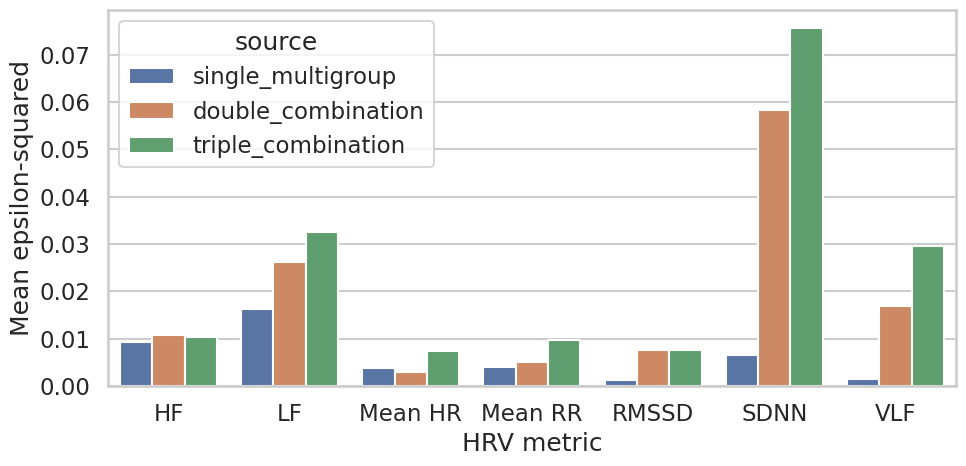

In [12]:
if not global_ranking_df.empty:
    plt.figure(figsize=(10, 5))
    sns.barplot(
        data=global_ranking_df,
        x="hrv_pretty",
        y="mean_eps2",
        hue="source"
    )
    plt.ylabel("Mean epsilon-squared")
    plt.xlabel("HRV metric")
    plt.tight_layout()
    plt.savefig(FIG_DIR / "hrv_global_discrimination_ranking.png", dpi=300)
    plt.show()

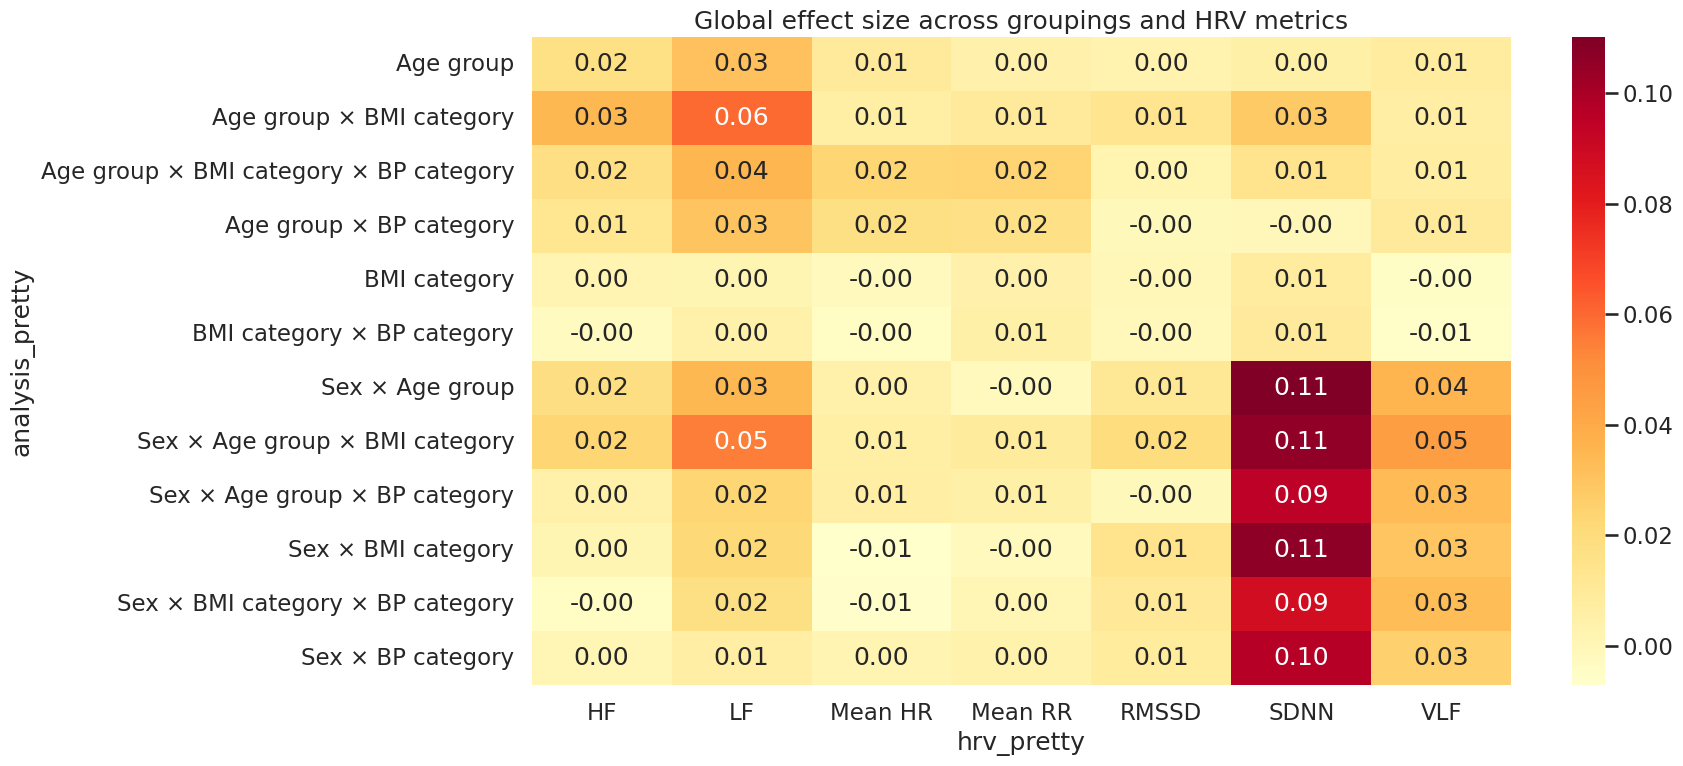

In [14]:
heatmap_rows = []

if not kruskal_df.empty:
    tmp = kruskal_df.copy()
    tmp["analysis"] = tmp["grouping_variable"]
    heatmap_rows.append(tmp[["analysis", "value_variable", "epsilon_squared", "significant_fdr"]])

if not double_kruskal_df.empty:
    tmp = double_kruskal_df.copy()
    tmp["analysis"] = tmp["combined_grouping"]
    heatmap_rows.append(tmp[["analysis", "value_variable", "epsilon_squared", "significant_fdr"]])

if not triple_kruskal_df.empty:
    tmp = triple_kruskal_df.copy()
    tmp["analysis"] = tmp["combined_grouping"]
    heatmap_rows.append(tmp[["analysis", "value_variable", "epsilon_squared", "significant_fdr"]])

if heatmap_rows:
    hm_df = pd.concat(heatmap_rows, ignore_index=True)
    hm_df["analysis_pretty"] = hm_df["analysis"].map(pretty_group_name)
    hm_df["hrv_pretty"] = hm_df["value_variable"].map(pretty_hrv_name)

    pivot_eps2 = hm_df.pivot_table(
        index="analysis_pretty",
        columns="hrv_pretty",
        values="epsilon_squared",
        aggfunc="mean"
    )

    plt.figure(figsize=(18, 8))
    sns.heatmap(pivot_eps2, annot=True, fmt=".2f", cmap="YlOrRd")
    plt.title("Global effect size across groupings and HRV metrics")
    plt.tight_layout()
    plt.savefig(FIG_DIR / "global_effectsize_heatmap.png", dpi=300)
    plt.show()

In [15]:
if not binary_df.empty:
    sig_binary = binary_df[binary_df["significant_fdr"]].copy()
    sig_binary["hrv_pretty"] = sig_binary["value_variable"].map(pretty_hrv_name)
    sig_binary["group_pretty"] = sig_binary["grouping_variable"].map(pretty_group_name)
sig_binary.sort_values("p_adj_fdr").head(30)

,grouping_variable,value_variable,group_a,group_b,n_a,n_b,median_a,median_b,u_stat,p_value,cliffs_delta,cliffs_magnitude,rank_biserial,p_adj_fdr,significant_fdr,hrv_pretty,group_pretty
2,sex,t2m_pre_sdnn,1,2,360,159,154.0,72.0,40023.5,4.472665e-13,0.398445,medium,-0.398445,3.130865e-12,True,SDNN,Sex
6,sex,t2m_pre_vlf,1,2,366,164,35.0,25.0,36530.5,6.335911e-05,0.217196,small,-0.217196,2.217569e-04,True,VLF,Sex
3,sex,t2m_pre_rmssd,1,2,362,160,14.0,12.5,33108.5,9.032589e-03,0.143249,negligible,-0.143249,1.746491e-02,True,RMSSD,Sex
5,sex,t2m_pre_lf,1,2,366,164,129.0,98.5,34211.5,9.979947e-03,0.139927,negligible,-0.139927,1.746491e-02,True,LF,Sex


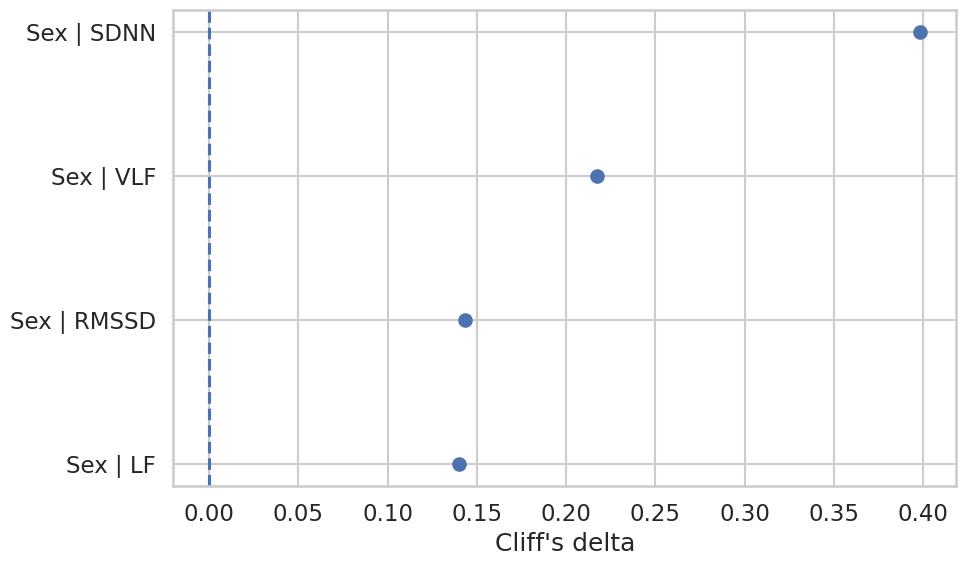

In [16]:
if not binary_df.empty:
    plot_df = binary_df[binary_df["significant_fdr"]].copy()
    plot_df["label"] = (
        plot_df["grouping_variable"].map(pretty_group_name)
        + " | "
        + plot_df["value_variable"].map(pretty_hrv_name)
    )
    plot_df = plot_df.sort_values("cliffs_delta")

    if len(plot_df) > 0:
        plt.figure(figsize=(10, max(6, 0.35 * len(plot_df))))
        plt.axvline(0, linestyle="--")
        plt.scatter(plot_df["cliffs_delta"], plot_df["label"])
        plt.xlabel("Cliff's delta")
        plt.ylabel("")
        plt.tight_layout()
        plt.savefig(FIG_DIR / "binary_cliffs_forestplot.png", dpi=300)
        plt.show()

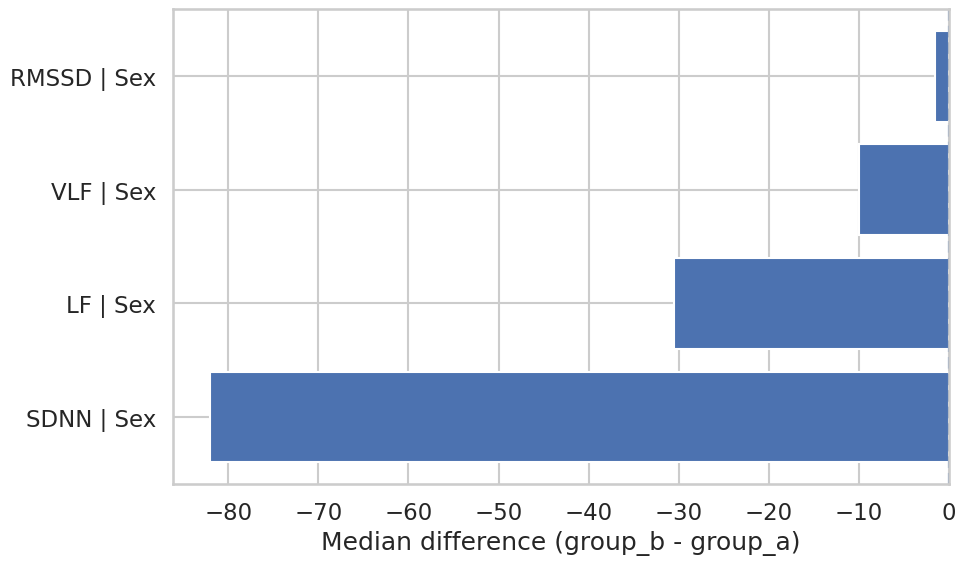

In [17]:
if not binary_df.empty:
    sig_bin = binary_df[binary_df["significant_fdr"]].copy()
    sig_bin["median_diff"] = sig_bin["median_b"] - sig_bin["median_a"]
    sig_bin["label"] = (
        sig_bin["value_variable"].map(pretty_hrv_name)
        + " | "
        + sig_bin["grouping_variable"].map(pretty_group_name)
    )
    sig_bin = sig_bin.sort_values("median_diff")

    if len(sig_bin) > 0:
        plt.figure(figsize=(10, max(6, 0.35 * len(sig_bin))))
        plt.axvline(0, linestyle="--")
        plt.barh(sig_bin["label"], sig_bin["median_diff"])
        plt.xlabel("Median difference (group_b - group_a)")
        plt.ylabel("")
        plt.tight_layout()
        plt.savefig(FIG_DIR / "binary_median_differences.png", dpi=300)
        plt.show()

In [18]:
if not kruskal_df.empty:
    sig_kruskal = kruskal_df[kruskal_df["significant_fdr"]].copy()
    sig_kruskal["hrv_pretty"] = sig_kruskal["value_variable"].map(pretty_hrv_name)
    sig_kruskal["group_pretty"] = sig_kruskal["grouping_variable"].map(pretty_group_name)
sig_kruskal.sort_values(["p_adj_fdr", "epsilon_squared"]).head(30)

,grouping_variable,value_variable,n_total,n_groups,h_stat,p_value,epsilon_squared,group_sizes,p_adj_fdr,significant_fdr,hrv_pretty,group_pretty
5,age_group,t2m_pre_lf,530,4,19.444978,0.000221,0.031264,"{'70-79': 261, '60-69': 219, '80+': 40, '<60':...",0.001548,True,LF,Age group
4,age_group,t2m_pre_hf,530,4,11.828574,0.007994,0.016784,"{'70-79': 261, '60-69': 219, '80+': 40, '<60':...",0.027979,True,HF,Age group


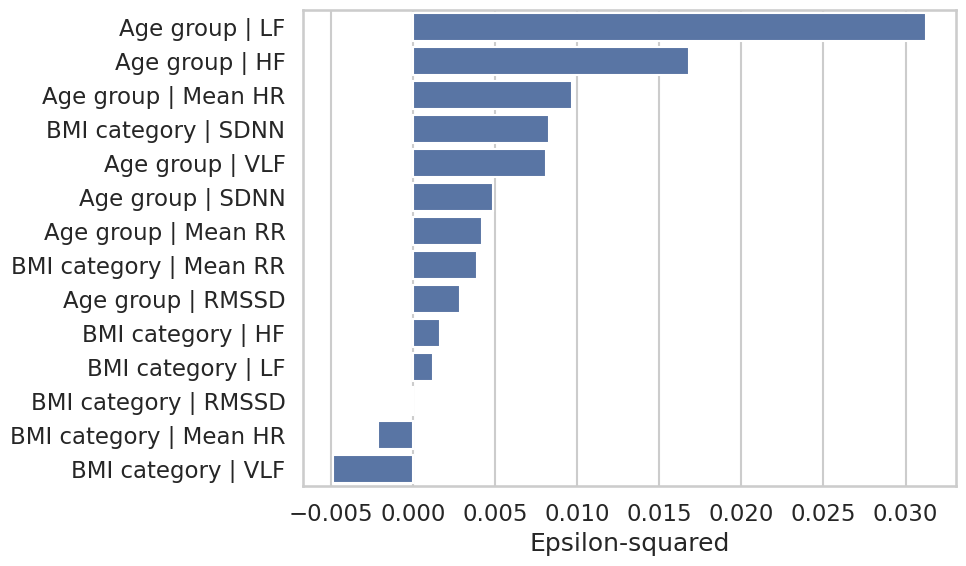

In [19]:
if not kruskal_df.empty:
    plot_df = kruskal_df.copy()
    plot_df["label"] = (
        plot_df["grouping_variable"].map(pretty_group_name)
        + " | "
        + plot_df["value_variable"].map(pretty_hrv_name)
    )
    plot_df = plot_df.sort_values("epsilon_squared", ascending=False)

    plt.figure(figsize=(10, max(6, 0.35 * len(plot_df))))
    sns.barplot(data=plot_df, y="label", x="epsilon_squared")
    plt.xlabel("Epsilon-squared")
    plt.ylabel("")
    plt.tight_layout()
    plt.savefig(FIG_DIR / "single_grouping_epsilon_squared.png", dpi=300)
    plt.show()

In [20]:
if not double_kruskal_df.empty:
    top_double = double_kruskal_df[double_kruskal_df["significant_fdr"]].copy()
    top_double["hrv_pretty"] = top_double["value_variable"].map(pretty_hrv_name)
    top_double["group_pretty"] = top_double["combined_grouping"].map(pretty_group_name)
top_double.sort_values(["p_adj_fdr", "epsilon_squared"]).head(30)

,grouping_variable,value_variable,n_total,n_groups,h_stat,p_value,epsilon_squared,group_sizes,p_adj_fdr,significant_fdr,combined_grouping,hrv_pretty,group_pretty
2,sex__age_group,t2m_pre_sdnn,517,7,62.178469,1.622659e-11,0.110154,"{'1 | 70-79': 163, '1 | 60-69': 160, '2 | 70-7...",1.135862e-10,True,sex__age_group,SDNN,Sex × Age group
16,sex__bp_cat,t2m_pre_sdnn,519,4,52.711849,2.111923e-11,0.096528,"{'1 | normal': 257, '2 | normal': 104, '1 | hi...",1.478346e-10,True,sex__bp_cat,SDNN,Sex × BP category
9,sex__bmi_cat,t2m_pre_sdnn,519,8,61.322907,8.212414e-11,0.106307,"{'1 | normal': 111, '2 | overweight': 57, '1 |...",5.748690e-10,True,sex__bmi_cat,SDNN,Sex × BMI category
26,age_group__bmi_cat,t2m_pre_lf,525,12,41.579853,1.914575e-05,0.059610,"{'70-79 | normal': 76, '60-69 | normal': 62, '...",1.340203e-04,True,age_group__bmi_cat,LF,Age group × BMI category
5,sex__age_group,t2m_pre_lf,528,7,24.089311,5.028663e-04,0.034720,"{'1 | 70-79': 167, '1 | 60-69': 162, '2 | 70-7...",1.173355e-03,True,sex__age_group,LF,Sex × Age group
6,sex__age_group,t2m_pre_vlf,528,7,24.585871,4.072946e-04,0.035673,"{'1 | 70-79': 167, '1 | 60-69': 162, '2 | 70-7...",1.173355e-03,True,sex__age_group,VLF,Sex × Age group
20,sex__bp_cat,t2m_pre_vlf,530,4,16.227945,1.018256e-03,0.025148,"{'1 | normal': 261, '2 | normal': 108, '1 | hi...",3.563895e-03,True,sex__bp_cat,VLF,Sex × BP category
13,sex__bmi_cat,t2m_pre_vlf,530,8,22.617240,1.986807e-03,0.029918,"{'1 | normal': 114, '2 | overweight': 57, '1 |...",6.953825e-03,True,sex__bmi_cat,VLF,Sex × BMI category
25,age_group__bmi_cat,t2m_pre_hf,525,12,28.749194,2.482396e-03,0.034599,"{'70-79 | normal': 76, '60-69 | normal': 62, '...",8.688387e-03,True,age_group__bmi_cat,HF,Age group × BMI category
33,age_group__bp_cat,t2m_pre_lf,530,7,21.689971,1.377863e-03,0.030000,"{'70-79 | normal': 180, '60-69 | normal': 153,...",9.645044e-03,True,age_group__bp_cat,LF,Age group × BP category


In [21]:
if not triple_kruskal_df.empty:
    top_triple = triple_kruskal_df[triple_kruskal_df["significant_fdr"]].copy()
    top_triple["hrv_pretty"] = top_triple["value_variable"].map(pretty_hrv_name)
    top_triple["group_pretty"] = top_triple["combined_grouping"].map(pretty_group_name)
top_triple.sort_values(["p_adj_fdr", "epsilon_squared"]).head(30)

,grouping_variable,value_variable,n_total,n_groups,h_stat,p_value,epsilon_squared,group_sizes,p_adj_fdr,significant_fdr,combined_grouping,hrv_pretty,group_pretty
9,sex__age_group__bp_cat,t2m_pre_sdnn,507,11,56.979451,1.344828e-08,0.094717,"{'1 | 70-79 | normal': 116, '1 | 60-69 | norma...",9.413797e-08,True,sex__age_group__bp_cat,SDNN,Sex × Age group × BP category
2,sex__age_group__bmi_cat,t2m_pre_sdnn,483,15,63.596058,2.720181e-08,0.105974,"{'1 | 70-79 | normal': 47, '1 | 60-69 | normal...",1.904127e-07,True,sex__age_group__bmi_cat,SDNN,Sex × Age group × BMI category
16,sex__bmi_cat__bp_cat,t2m_pre_sdnn,509,13,55.605748,1.409142e-07,0.087915,"{'1 | normal | normal': 82, '2 | overweight | ...",9.863993e-07,True,sex__bmi_cat__bp_cat,SDNN,Sex × BMI category × BP category
5,sex__age_group__bmi_cat,t2m_pre_lf,493,15,40.238173,2.341896e-04,0.054892,"{'1 | 70-79 | normal': 50, '1 | 60-69 | normal...",8.196635e-04,True,sex__age_group__bmi_cat,LF,Sex × Age group × BMI category
6,sex__age_group__bmi_cat,t2m_pre_vlf,493,15,35.515656,1.232494e-03,0.045012,"{'1 | 70-79 | normal': 50, '1 | 60-69 | normal...",2.875820e-03,True,sex__age_group__bmi_cat,VLF,Sex × Age group × BMI category
13,sex__age_group__bp_cat,t2m_pre_vlf,517,11,26.841309,2.759165e-03,0.033283,"{'1 | 70-79 | normal': 119, '1 | 60-69 | norma...",9.657077e-03,True,sex__age_group__bp_cat,VLF,Sex × Age group × BP category
20,sex__bmi_cat__bp_cat,t2m_pre_vlf,520,13,28.617463,4.488852e-03,0.032776,"{'1 | normal | normal': 85, '2 | overweight | ...",1.571098e-02,True,sex__bmi_cat__bp_cat,VLF,Sex × BMI category × BP category
12,sex__age_group__bp_cat,t2m_pre_lf,517,11,21.715358,1.662219e-02,0.023153,"{'1 | 70-79 | normal': 119, '1 | 60-69 | norma...",3.878511e-02,True,sex__age_group__bp_cat,LF,Sex × Age group × BP category
26,age_group__bmi_cat__bp_cat,t2m_pre_lf,492,15,30.859388,5.800234e-03,0.035345,"{'70-79 | normal | normal': 57, '60-69 | norma...",4.060164e-02,True,age_group__bmi_cat__bp_cat,LF,Age group × BMI category × BP category


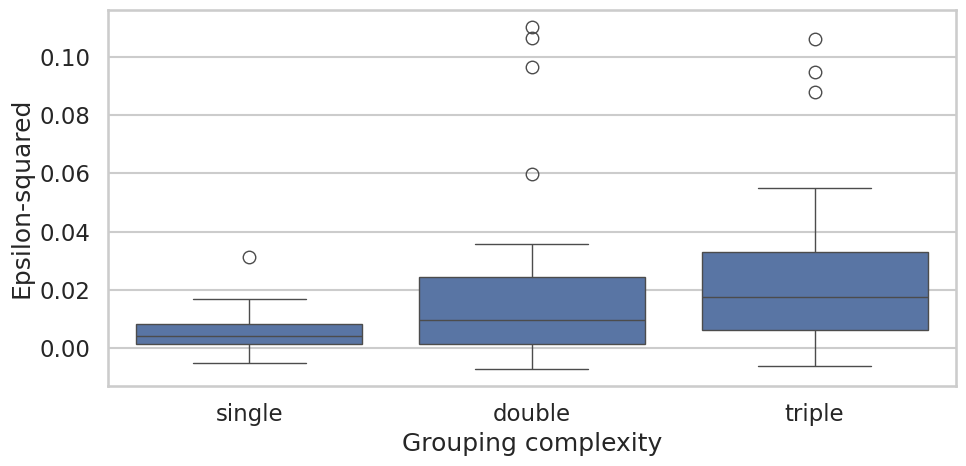

In [22]:
comparison_rows = []

if not kruskal_df.empty:
    tmp = kruskal_df.copy()
    tmp["level"] = "single"
    comparison_rows.append(tmp[["value_variable", "epsilon_squared", "level"]])

if not double_kruskal_df.empty:
    tmp = double_kruskal_df.copy()
    tmp["level"] = "double"
    comparison_rows.append(tmp[["value_variable", "epsilon_squared", "level"]])

if not triple_kruskal_df.empty:
    tmp = triple_kruskal_df.copy()
    tmp["level"] = "triple"
    comparison_rows.append(tmp[["value_variable", "epsilon_squared", "level"]])

if comparison_rows:
    comparison_df = pd.concat(comparison_rows, ignore_index=True)
    comparison_df["hrv_pretty"] = comparison_df["value_variable"].map(pretty_hrv_name)

    plt.figure(figsize=(10, 5))
    sns.boxplot(data=comparison_df, x="level", y="epsilon_squared")
    plt.ylabel("Epsilon-squared")
    plt.xlabel("Grouping complexity")
    plt.tight_layout()
    plt.savefig(FIG_DIR / "epsilon_squared_by_grouping_complexity.png", dpi=300)
    plt.show()

In [23]:
def get_top_hrv_for_grouping(results_df, grouping_col="grouping_variable", top_n=3):
    if results_df.empty:
        return pd.DataFrame()

    out = []
    for g, sub in results_df.groupby(grouping_col):
        sub = sub.sort_values(["significant_fdr", "p_adj_fdr", "epsilon_squared"], ascending=[False, True, False])
        out.append(sub.head(top_n))
    return pd.concat(out, ignore_index=True)

In [24]:
if not kruskal_df.empty:
    top_by_grouping = get_top_hrv_for_grouping(kruskal_df, grouping_col="grouping_variable", top_n=3)
    top_by_grouping["group_pretty"] = top_by_grouping["grouping_variable"].map(pretty_group_name)
    top_by_grouping["hrv_pretty"] = top_by_grouping["value_variable"].map(pretty_hrv_name)
top_by_grouping

,grouping_variable,value_variable,n_total,n_groups,h_stat,p_value,epsilon_squared,group_sizes,p_adj_fdr,significant_fdr,group_pretty,hrv_pretty
0,age_group,t2m_pre_lf,530,4,19.444978,0.000221,0.031264,"{'70-79': 261, '60-69': 219, '80+': 40, '<60':...",0.001548,True,Age group,LF
1,age_group,t2m_pre_hf,530,4,11.828574,0.007994,0.016784,"{'70-79': 261, '60-69': 219, '80+': 40, '<60':...",0.027979,True,Age group,HF
2,age_group,t2m_pre_mean_hr,529,4,8.089549,0.044197,0.009694,"{'70-79': 261, '60-69': 218, '80+': 40, '<60':...",0.103126,False,Age group,Mean HR
3,bmi_cat,t2m_pre_sdnn,519,4,7.261466,0.064015,0.008275,"{'normal': 153, 'overweight': 160, 'obesity': ...",0.448104,False,BMI category,SDNN
4,bmi_cat,t2m_pre_mean_rr,530,4,5.056120,0.167734,0.003909,"{'normal': 161, 'overweight': 162, 'obesity': ...",0.533046,False,BMI category,Mean RR
5,bmi_cat,t2m_pre_hf,530,4,3.858375,0.277169,0.001632,"{'normal': 161, 'overweight': 162, 'obesity': ...",0.533046,False,BMI category,HF


In [25]:
if not kruskal_df.empty:
    top_by_grouping.to_csv(TABLE_DIR / "top_hrv_by_single_grouping.csv", index=False)

In [26]:
if not double_kruskal_df.empty:
    top_double_by_grouping = get_top_hrv_for_grouping(double_kruskal_df, grouping_col="combined_grouping", top_n=3)
    top_double_by_grouping["group_pretty"] = top_double_by_grouping["combined_grouping"].map(pretty_group_name)
    top_double_by_grouping["hrv_pretty"] = top_double_by_grouping["value_variable"].map(pretty_hrv_name)
top_double_by_grouping

,grouping_variable,value_variable,n_total,n_groups,h_stat,p_value,epsilon_squared,group_sizes,p_adj_fdr,significant_fdr,combined_grouping,group_pretty,hrv_pretty
0,age_group__bmi_cat,t2m_pre_lf,525,12,41.579853,1.914575e-05,0.059610,"{'70-79 | normal': 76, '60-69 | normal': 62, '...",1.340203e-04,True,age_group__bmi_cat,Age group × BMI category,LF
1,age_group__bmi_cat,t2m_pre_hf,525,12,28.749194,2.482396e-03,0.034599,"{'70-79 | normal': 76, '60-69 | normal': 62, '...",8.688387e-03,True,age_group__bmi_cat,Age group × BMI category,HF
2,age_group__bmi_cat,t2m_pre_sdnn,514,12,25.117159,8.763350e-03,0.028122,"{'70-79 | normal': 72, '60-69 | normal': 59, '...",2.044782e-02,True,age_group__bmi_cat,Age group × BMI category,SDNN
3,age_group__bp_cat,t2m_pre_lf,530,7,21.689971,1.377863e-03,0.030000,"{'70-79 | normal': 180, '60-69 | normal': 153,...",9.645044e-03,True,age_group__bp_cat,Age group × BP category,LF
4,age_group__bp_cat,t2m_pre_mean_hr,529,7,15.130604,1.926487e-02,0.017492,"{'70-79 | normal': 180, '60-69 | normal': 152,...",5.666077e-02,False,age_group__bp_cat,Age group × BP category,Mean HR
5,age_group__bp_cat,t2m_pre_mean_rr,530,7,14.525841,2.428319e-02,0.016302,"{'70-79 | normal': 180, '60-69 | normal': 153,...",5.666077e-02,False,age_group__bp_cat,Age group × BP category,Mean RR
6,bmi_cat__bp_cat,t2m_pre_sdnn,519,8,11.914776,1.033966e-01,0.009618,"{'normal | normal': 114, 'overweight | normal'...",5.442697e-01,False,bmi_cat__bp_cat,BMI category × BP category,SDNN
7,bmi_cat__bp_cat,t2m_pre_mean_rr,530,8,9.766278,2.022097e-01,0.005299,"{'normal | normal': 121, 'overweight | normal'...",5.442697e-01,False,bmi_cat__bp_cat,BMI category × BP category,Mean RR
8,bmi_cat__bp_cat,t2m_pre_lf,530,8,9.278739,2.332585e-01,0.004365,"{'normal | normal': 121, 'overweight | normal'...",5.442697e-01,False,bmi_cat__bp_cat,BMI category × BP category,LF
9,sex__age_group,t2m_pre_sdnn,517,7,62.178469,1.622659e-11,0.110154,"{'1 | 70-79': 163, '1 | 60-69': 160, '2 | 70-7...",1.135862e-10,True,sex__age_group,Sex × Age group,SDNN


In [27]:
if not triple_kruskal_df.empty:
    top_triple_by_grouping = get_top_hrv_for_grouping(triple_kruskal_df, grouping_col="combined_grouping", top_n=3)
    top_triple_by_grouping["group_pretty"] = top_triple_by_grouping["combined_grouping"].map(pretty_group_name)
    top_triple_by_grouping["hrv_pretty"] = top_triple_by_grouping["value_variable"].map(pretty_hrv_name)
top_triple_by_grouping

,grouping_variable,value_variable,n_total,n_groups,h_stat,p_value,epsilon_squared,group_sizes,p_adj_fdr,significant_fdr,combined_grouping,group_pretty,hrv_pretty
0,age_group__bmi_cat__bp_cat,t2m_pre_lf,492,15,30.859388,5.800234e-03,0.035345,"{'70-79 | normal | normal': 57, '60-69 | norma...",4.060164e-02,True,age_group__bmi_cat__bp_cat,Age group × BMI category × BP category,LF
1,age_group__bmi_cat__bp_cat,t2m_pre_mean_rr,492,15,25.401402,3.080537e-02,0.023902,"{'70-79 | normal | normal': 57, '60-69 | norma...",8.163505e-02,False,age_group__bmi_cat__bp_cat,Age group × BMI category × BP category,Mean RR
2,age_group__bmi_cat__bp_cat,t2m_pre_mean_hr,491,15,24.957784,3.498645e-02,0.023021,"{'70-79 | normal | normal': 57, '60-69 | norma...",8.163505e-02,False,age_group__bmi_cat__bp_cat,Age group × BMI category × BP category,Mean HR
3,sex__age_group__bmi_cat,t2m_pre_sdnn,483,15,63.596058,2.720181e-08,0.105974,"{'1 | 70-79 | normal': 47, '1 | 60-69 | normal...",1.904127e-07,True,sex__age_group__bmi_cat,Sex × Age group × BMI category,SDNN
4,sex__age_group__bmi_cat,t2m_pre_lf,493,15,40.238173,2.341896e-04,0.054892,"{'1 | 70-79 | normal': 50, '1 | 60-69 | normal...",8.196635e-04,True,sex__age_group__bmi_cat,Sex × Age group × BMI category,LF
5,sex__age_group__bmi_cat,t2m_pre_vlf,493,15,35.515656,1.232494e-03,0.045012,"{'1 | 70-79 | normal': 50, '1 | 60-69 | normal...",2.875820e-03,True,sex__age_group__bmi_cat,Sex × Age group × BMI category,VLF
6,sex__age_group__bp_cat,t2m_pre_sdnn,507,11,56.979451,1.344828e-08,0.094717,"{'1 | 70-79 | normal': 116, '1 | 60-69 | norma...",9.413797e-08,True,sex__age_group__bp_cat,Sex × Age group × BP category,SDNN
7,sex__age_group__bp_cat,t2m_pre_vlf,517,11,26.841309,2.759165e-03,0.033283,"{'1 | 70-79 | normal': 119, '1 | 60-69 | norma...",9.657077e-03,True,sex__age_group__bp_cat,Sex × Age group × BP category,VLF
8,sex__age_group__bp_cat,t2m_pre_lf,517,11,21.715358,1.662219e-02,0.023153,"{'1 | 70-79 | normal': 119, '1 | 60-69 | norma...",3.878511e-02,True,sex__age_group__bp_cat,Sex × Age group × BP category,LF
9,sex__bmi_cat__bp_cat,t2m_pre_sdnn,509,13,55.605748,1.409142e-07,0.087915,"{'1 | normal | normal': 82, '2 | overweight | ...",9.863993e-07,True,sex__bmi_cat__bp_cat,Sex × BMI category × BP category,SDNN


In [48]:
def plot_significant_boxplots(
    df_in,
    results_df,
    grouping_col,
    value_col_name="value_variable",
    top_n=6,
    sort_col="epsilon_squared",
    file_prefix="significant_boxplot"
):
    """
    Plot boxplots for the top significant results from a statistical results table.

    Parameters
    ----------
    df_in : pd.DataFrame
        Original dataset containing the variables to plot.
    results_df : pd.DataFrame
        Results table containing at least:
        - grouping_col
        - value_col_name
        - significant_fdr
        - p_adj_fdr
        - sort_col
    grouping_col : str
        Name of the column in results_df that stores the grouping variable name.
    value_col_name : str, default="value_variable"
        Name of the column in results_df that stores the response/value variable.
    top_n : int, default=6
        Number of top significant results to plot.
    sort_col : str, default="epsilon_squared"
        Column used as secondary sorting criterion.
    file_prefix : str, default="significant_boxplot"
        Prefix used when saving figures.
    """
    if results_df.empty:
        print("results_df is empty.")
        return

    # Remove duplicated columns if they exist
    results_df = results_df.loc[:, ~results_df.columns.duplicated()].copy()

    required_cols = [grouping_col, value_col_name, "significant_fdr", "p_adj_fdr", sort_col]
    missing_required = [c for c in required_cols if c not in results_df.columns]

    if missing_required:
        print(f"Missing required columns in results_df: {missing_required}")
        return

    sub = results_df[results_df["significant_fdr"]].copy()

    if sub.empty:
        print("No significant results found.")
        return

    sub = sub.sort_values(["p_adj_fdr", sort_col], ascending=[True, False]).head(top_n)

    for _, row in sub.iterrows():
        g = row[grouping_col]
        v = row[value_col_name]

        # Extra safety in case pandas still returns non-scalars
        if isinstance(g, pd.Series):
            g = g.iloc[0]
        if isinstance(v, pd.Series):
            v = v.iloc[0]

        if pd.isna(g) or pd.isna(v):
            continue

        g = str(g)
        v = str(v)

        if g not in df_in.columns or v not in df_in.columns:
            print(f"Skipping plot because '{g}' or '{v}' is not present in df_in.")
            continue

        plot_df = df_in[[g, v]].dropna().copy()

        if plot_df.empty:
            print(f"Skipping plot for {g} vs {v} because data is empty after dropna.")
            continue

        plt.figure(figsize=(8, 5))
        sns.boxplot(data=plot_df, x=g, y=v)

        if g == "age_group":
            plt.xticks(rotation=0)
        else:
            plt.xticks(rotation=30, ha="right")

        p_adj = row["p_adj_fdr"]
        title = f"{pretty_hrv_name(v)} by {pretty_group_name(g)} | FDR={p_adj:.3g}"
        plt.title(title)
        plt.xlabel(pretty_group_name(g))
        plt.ylabel(pretty_hrv_name(v))
        plt.tight_layout()

        plt.savefig(FIG_DIR / f"{file_prefix}_{g}_{v}.png", dpi=300)
        plt.show()

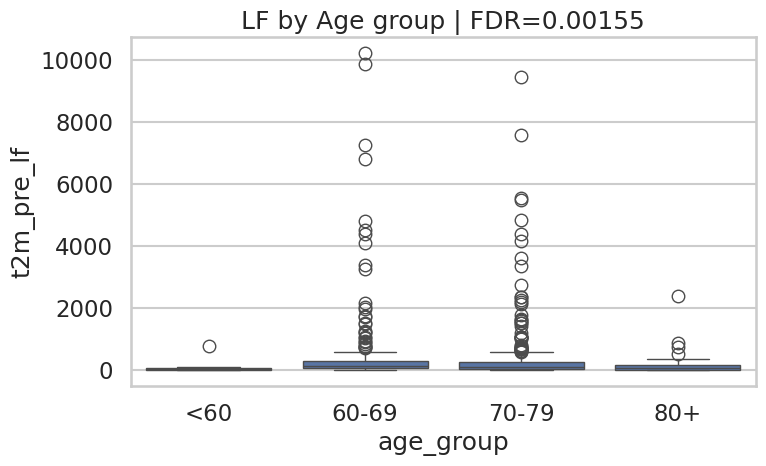

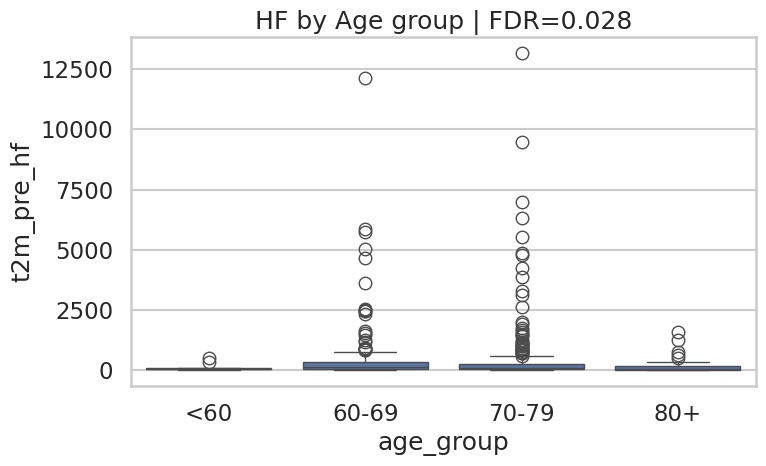

In [29]:
if not kruskal_df.empty:
    plot_significant_boxplots(
        df_in=df,
        results_df=kruskal_df,
        grouping_col="grouping_variable",
        value_col_name="value_variable",
        top_n=8,
        sort_col="epsilon_squared",
        file_prefix="single"
    )

In [30]:
def create_combined_column(df_in, cols):
    name = "__".join(cols)
    tmp = df_in.copy()
    tmp[name] = tmp[list(cols)].astype(str).agg(" | ".join, axis=1)
    mask_missing = tmp[list(cols)].isna().any(axis=1)
    tmp.loc[mask_missing, name] = np.nan
    return tmp, name

In [31]:
combined_defs = [
    ("sex", "age_group"),
    ("sex", "bmi_cat"),
    ("sex", "bp_cat"),
    ("age_group", "bmi_cat"),
    ("age_group", "bp_cat"),
    ("bmi_cat", "bp_cat"),
    ("sex", "age_group", "bmi_cat"),
    ("sex", "age_group", "bp_cat"),
    ("sex", "bmi_cat", "bp_cat"),
    ("age_group", "bmi_cat", "bp_cat"),
]

for comb in combined_defs:
    if all(c in df.columns for c in comb):
        df, name = create_combined_column(df, comb)

combined_cols = [c for c in df.columns if "__" in c]
combined_cols[:10]

['sex__age_group',
 'sex__bmi_cat',
 'sex__bp_cat',
 'age_group__bmi_cat',
 'age_group__bp_cat',
 'bmi_cat__bp_cat',
 'sex__age_group__bmi_cat',
 'sex__age_group__bp_cat',
 'sex__bmi_cat__bp_cat',
 'age_group__bmi_cat__bp_cat']

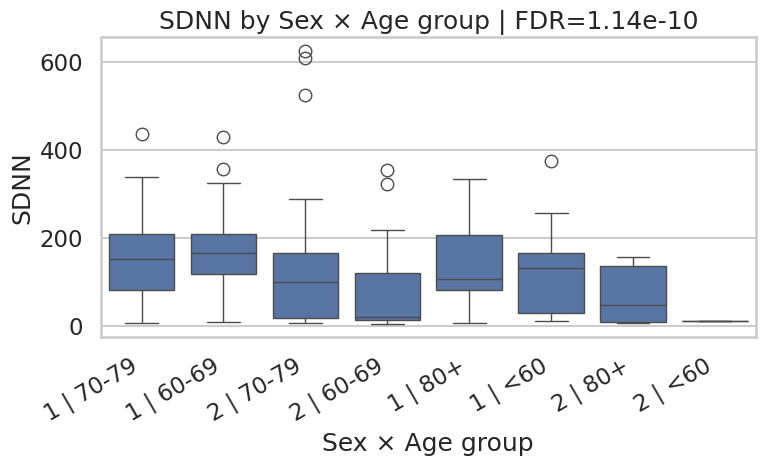

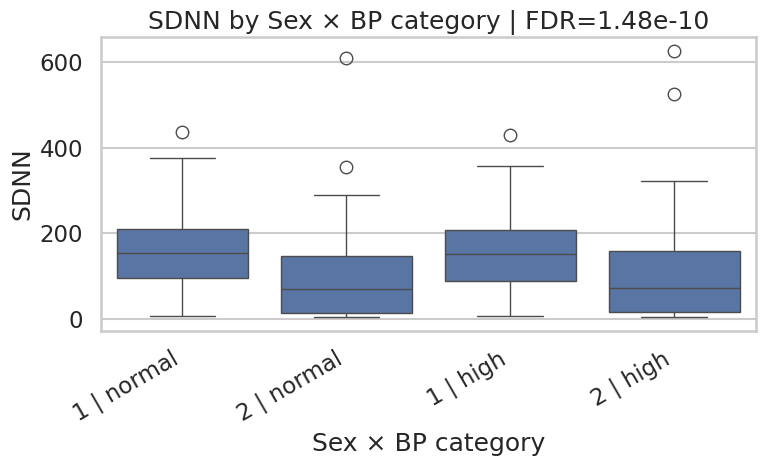

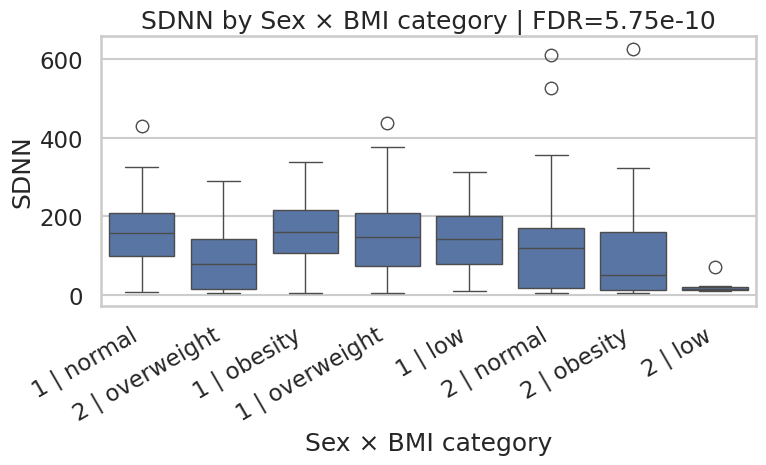

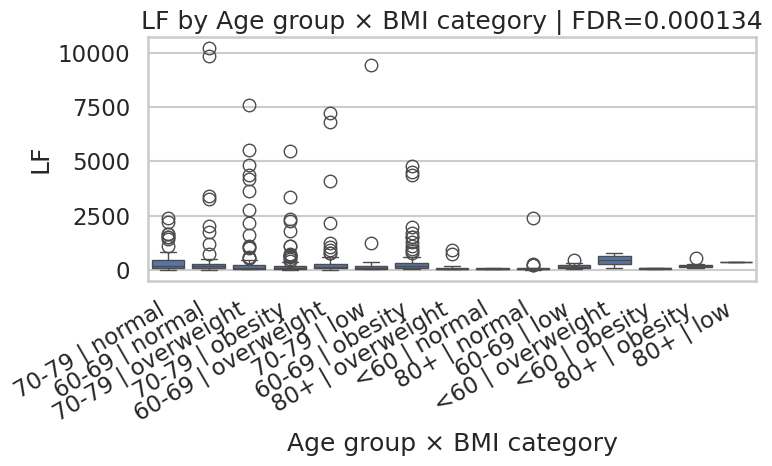

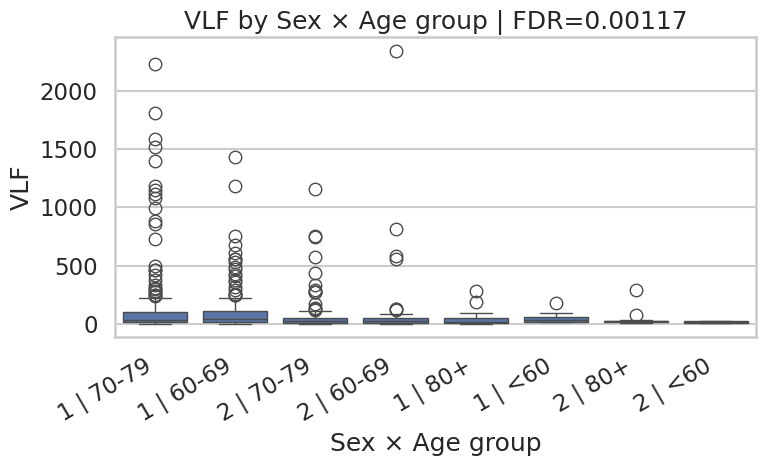

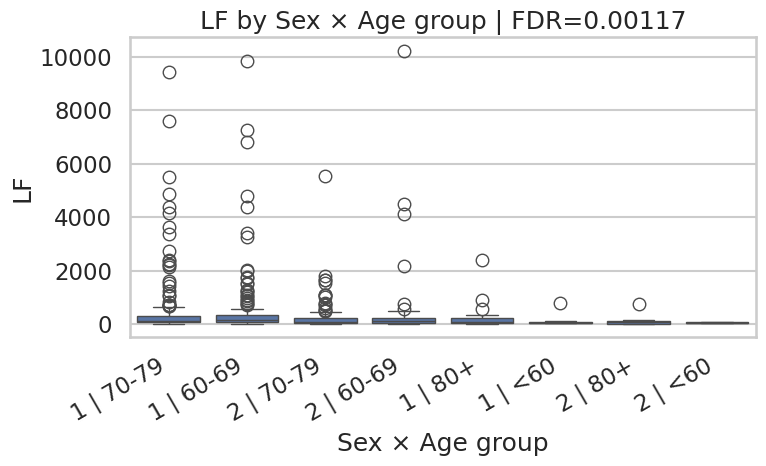

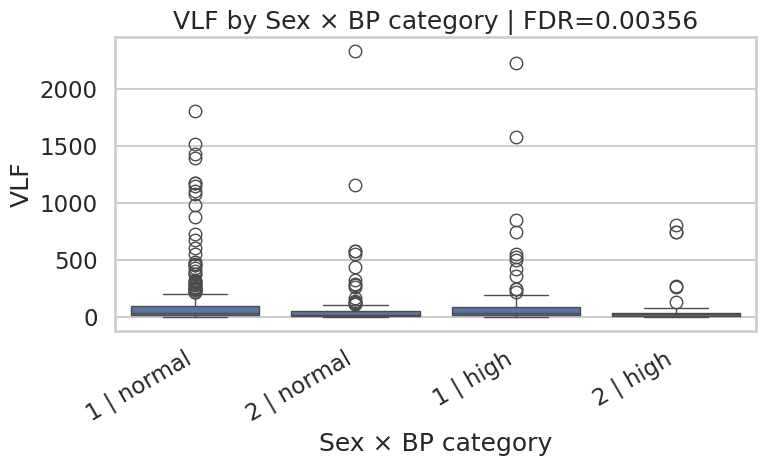

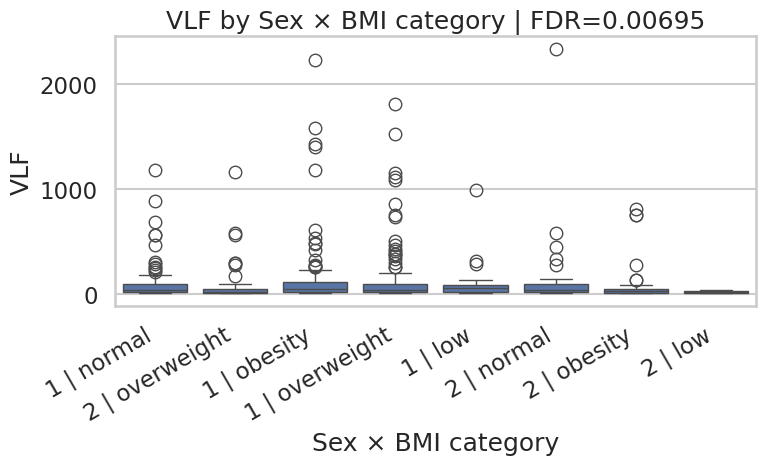

In [49]:
if not double_kruskal_df.empty:
    plot_significant_boxplots(
        df_in=df,
        results_df=double_kruskal_df.rename(columns={"combined_grouping": "grouping_variable"}),
        grouping_col="grouping_variable",
        value_col_name="value_variable",
        top_n=8,
        sort_col="epsilon_squared",
        file_prefix="double"
    )

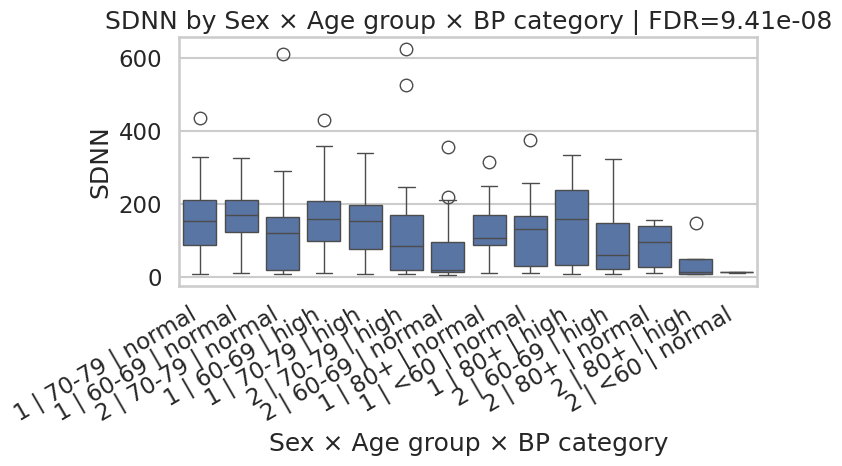

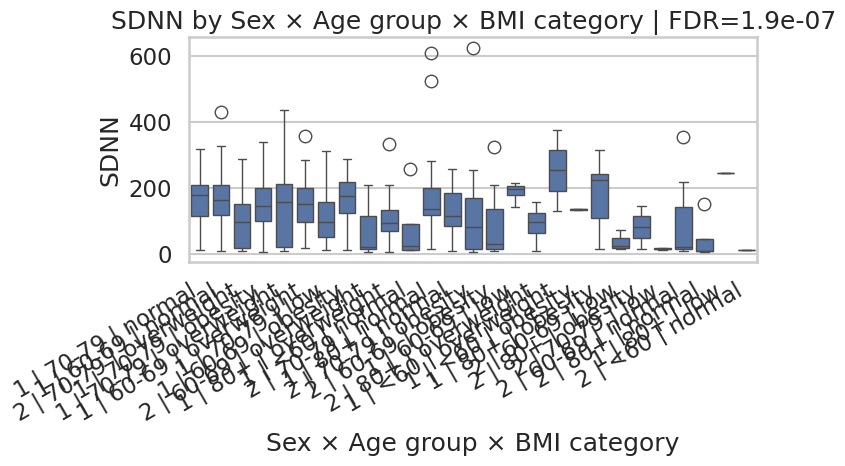

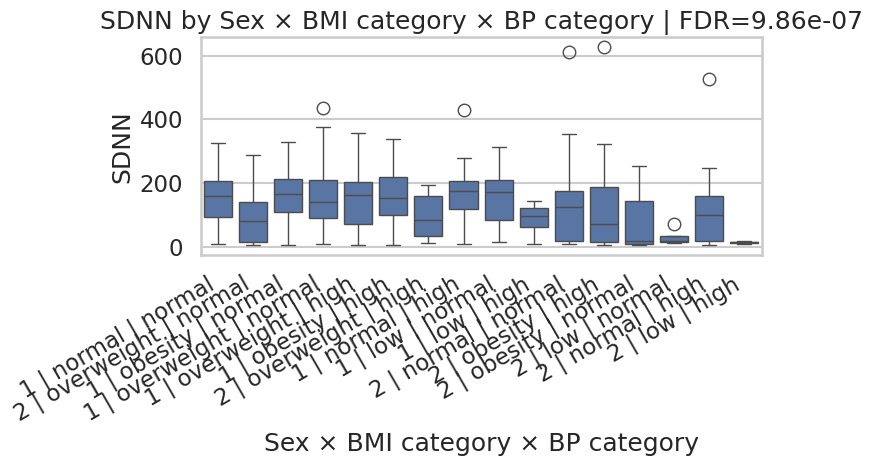

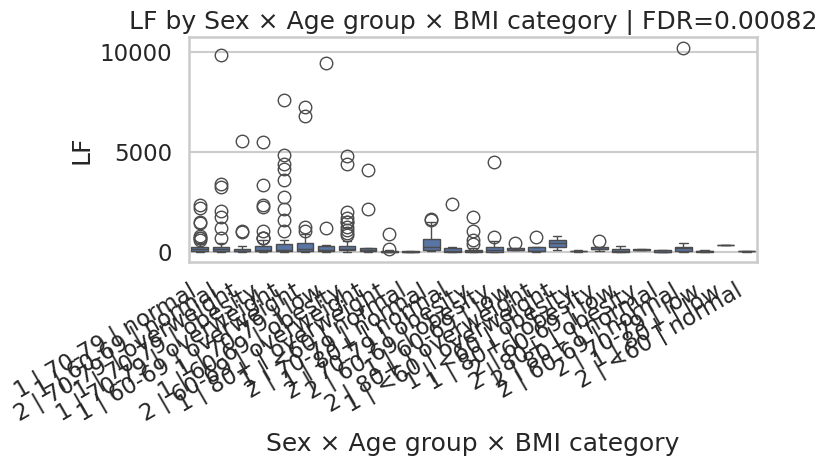

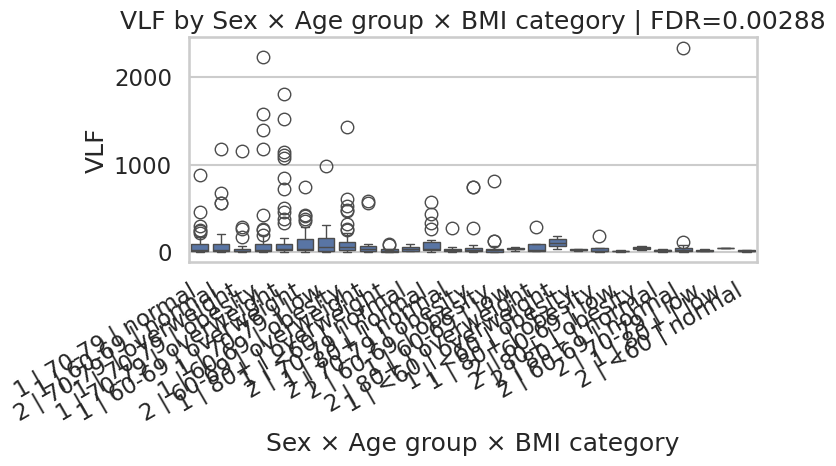

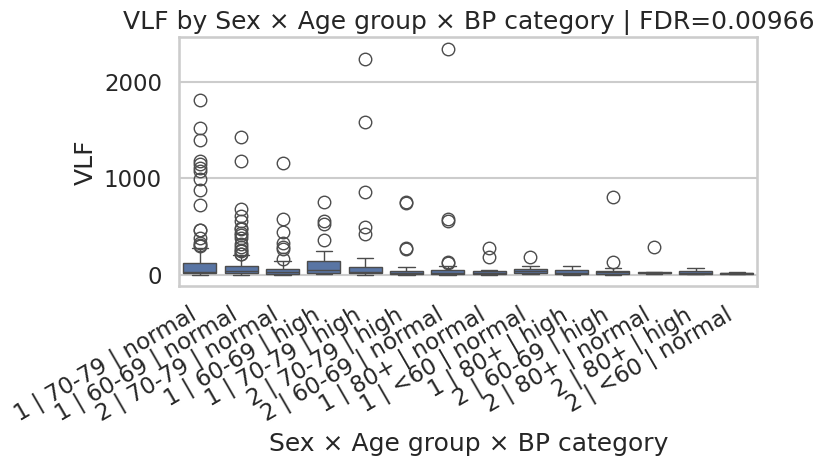

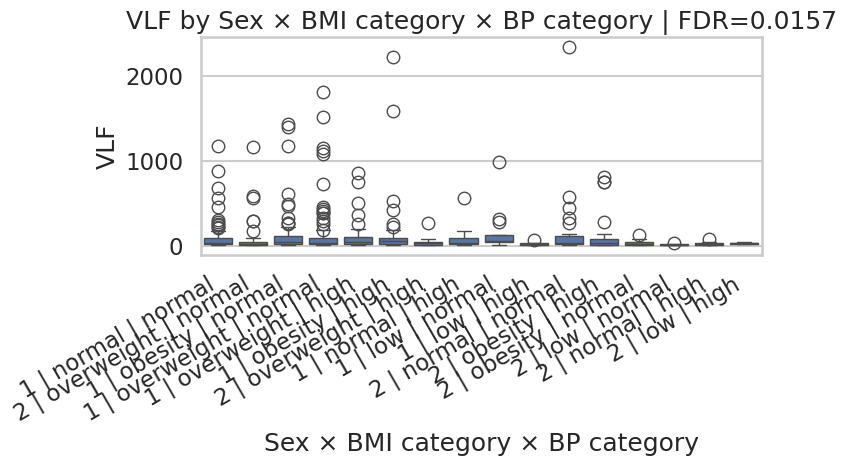

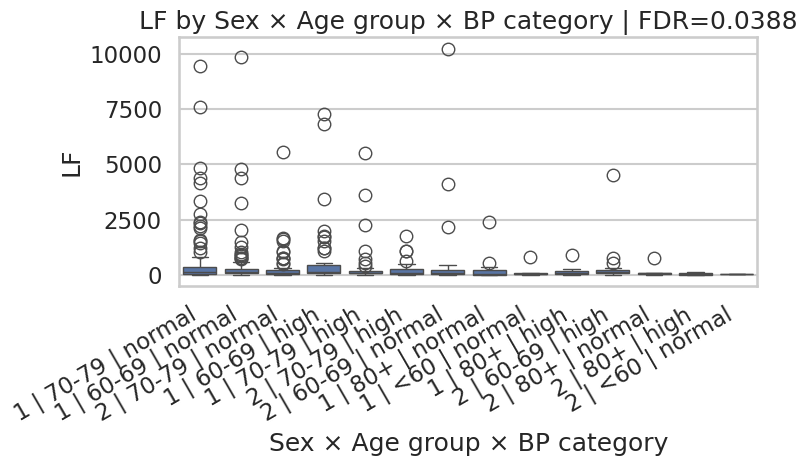

In [50]:
if not triple_kruskal_df.empty:
    plot_significant_boxplots(
        df_in=df,
        results_df=triple_kruskal_df.rename(columns={"combined_grouping": "grouping_variable"}),
        grouping_col="grouping_variable",
        value_col_name="value_variable",
        top_n=8,
        sort_col="epsilon_squared",
        file_prefix="triple"
    )

In [34]:
if not pairwise_df.empty:
    sig_pairwise = pairwise_df[pairwise_df["significant_fdr"]].copy()
    sig_pairwise["hrv_pretty"] = sig_pairwise["value_variable"].map(pretty_hrv_name)
    sig_pairwise["group_pretty"] = sig_pairwise["grouping_variable"].map(pretty_group_name)
sig_pairwise.sort_values(["p_adj_fdr", "cliffs_delta"]).head(40)

,grouping_variable,value_variable,group_a,group_b,n_a,n_b,median_a,median_b,p_value_raw,cliffs_delta,cliffs_magnitude,p_adj_fdr,significant_fdr,hrv_pretty,group_pretty
33,age_group,t2m_pre_lf,60-69,80+,219,40,149.0,73.0,0.000366,0.354566,medium,0.002195,True,LF,Age group
31,age_group,t2m_pre_lf,70-79,80+,261,40,111.0,73.0,0.005633,0.271935,small,0.013498,True,LF,Age group
34,age_group,t2m_pre_lf,60-69,<60,219,10,149.0,53.5,0.006749,0.507306,large,0.013498,True,LF,Age group
27,age_group,t2m_pre_hf,60-69,80+,219,40,128.0,50.0,0.002638,0.299201,small,0.015831,True,HF,Age group
39,age_group,t2m_pre_vlf,60-69,80+,219,40,39.0,21.5,0.007638,0.265411,small,0.045828,True,VLF,Age group


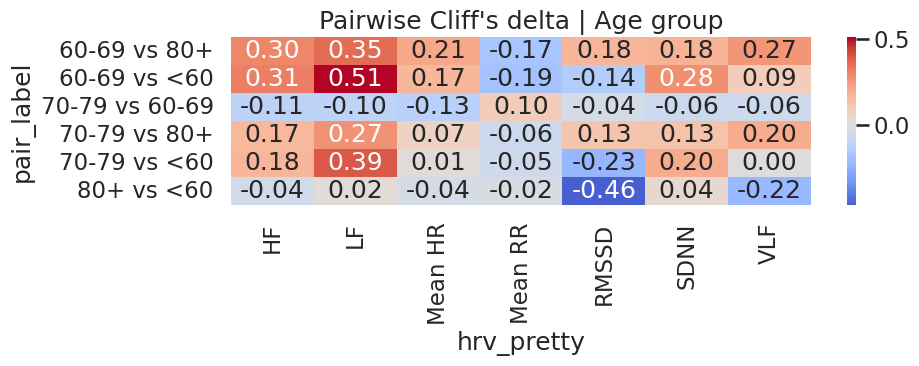

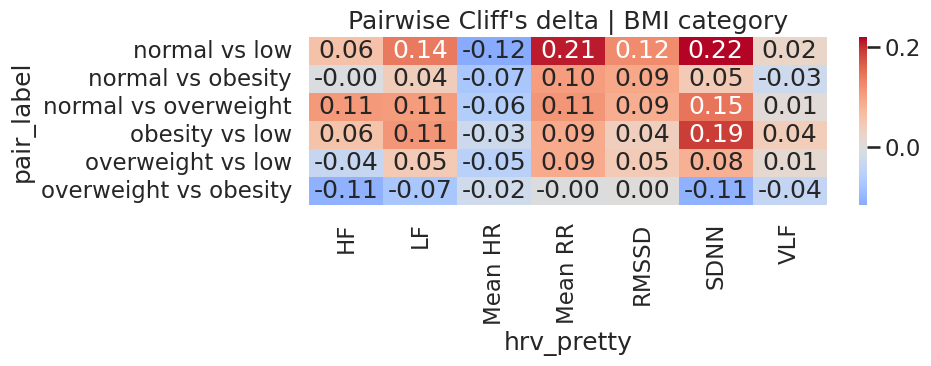

In [35]:
if not pairwise_df.empty:
    pairwise_df["pair_label"] = pairwise_df["group_a"].astype(str) + " vs " + pairwise_df["group_b"].astype(str)

    for grouping in pairwise_df["grouping_variable"].dropna().unique():
        sub = pairwise_df[pairwise_df["grouping_variable"] == grouping].copy()
        if sub.empty:
            continue

        sub["hrv_pretty"] = sub["value_variable"].map(pretty_hrv_name)

        pivot = sub.pivot_table(
            index="pair_label",
            columns="hrv_pretty",
            values="cliffs_delta",
            aggfunc="mean"
        )

        plt.figure(figsize=(10, max(4, 0.5 * len(pivot))))
        sns.heatmap(pivot, annot=True, fmt=".2f", cmap="coolwarm", center=0)
        plt.title(f"Pairwise Cliff's delta | {pretty_group_name(grouping)}")
        plt.tight_layout()
        plt.savefig(FIG_DIR / f"pairwise_cliff_heatmap_{grouping}.png", dpi=300)
        plt.show()

In [36]:
if not dunn_df.empty:
    sig_dunn = dunn_df[dunn_df["p_adj"] < 0.05].copy()
    sig_dunn["hrv_pretty"] = sig_dunn["value_variable"].map(pretty_hrv_name)
    sig_dunn["group_pretty"] = sig_dunn["grouping_variable"].map(pretty_group_name)
sig_dunn.sort_values("p_adj").head(40)

,grouping_variable,value_variable,group_a,group_b,p_adj,hrv_pretty,group_pretty
34,age_group,t2m_pre_lf,60-69,80+,0.001307,LF,Age group
30,age_group,t2m_pre_lf,<60,60-69,0.017233,LF,Age group
35,age_group,t2m_pre_lf,70-79,80+,0.017233,LF,Age group
28,age_group,t2m_pre_hf,60-69,80+,0.019755,HF,Age group
40,age_group,t2m_pre_vlf,60-69,80+,0.045641,VLF,Age group


In [37]:
if not dunn_df.empty:
    sig_counts = (
        dunn_df.assign(significant=lambda x: x["p_adj"] < 0.05)
        .groupby(["grouping_variable", "value_variable"])["significant"]
        .sum()
        .reset_index()
    )
    sig_counts["group_pretty"] = sig_counts["grouping_variable"].map(pretty_group_name)
    sig_counts["hrv_pretty"] = sig_counts["value_variable"].map(pretty_hrv_name)
sig_counts.sort_values("significant", ascending=False)

,grouping_variable,value_variable,significant,group_pretty,hrv_pretty
1,age_group,t2m_pre_lf,3,Age group,LF
0,age_group,t2m_pre_hf,1,Age group,HF
6,age_group,t2m_pre_vlf,1,Age group,VLF
2,age_group,t2m_pre_mean_hr,0,Age group,Mean HR
4,age_group,t2m_pre_rmssd,0,Age group,RMSSD
3,age_group,t2m_pre_mean_rr,0,Age group,Mean RR
5,age_group,t2m_pre_sdnn,0,Age group,SDNN
7,bmi_cat,t2m_pre_hf,0,BMI category,HF
8,bmi_cat,t2m_pre_lf,0,BMI category,LF
9,bmi_cat,t2m_pre_mean_hr,0,BMI category,Mean HR


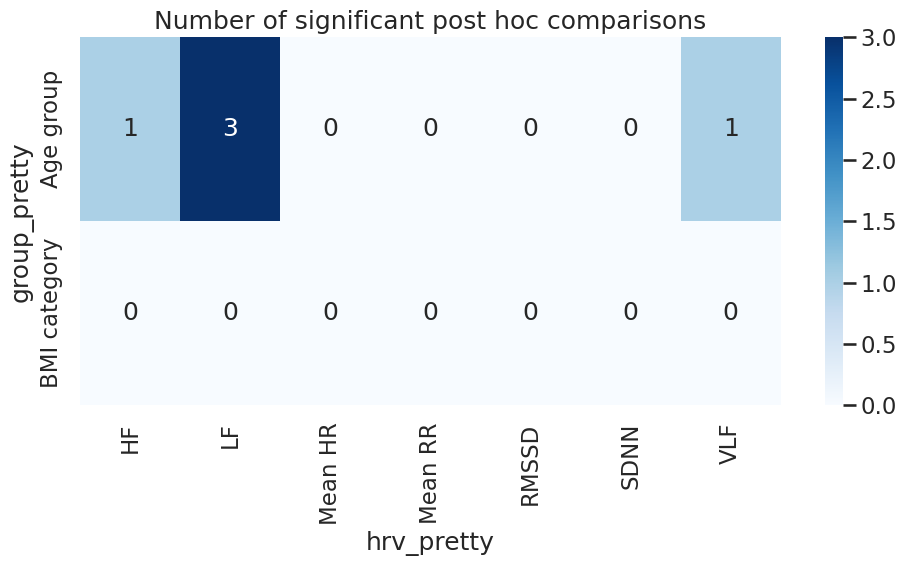

In [38]:
if not dunn_df.empty:
    sig_counts_pivot = sig_counts.pivot_table(
        index="group_pretty",
        columns="hrv_pretty",
        values="significant",
        aggfunc="sum"
    )

    plt.figure(figsize=(10, 6))
    sns.heatmap(sig_counts_pivot, annot=True, fmt=".0f", cmap="Blues")
    plt.title("Number of significant post hoc comparisons")
    plt.tight_layout()
    plt.savefig(FIG_DIR / "dunn_significant_counts_heatmap.png", dpi=300)
    plt.show()

In [39]:
candidate_figures = []

if not kruskal_df.empty:
    tmp = kruskal_df[kruskal_df["significant_fdr"]].copy()
    tmp["analysis_type"] = "single"
    tmp["group_label"] = tmp["grouping_variable"].map(pretty_group_name)
    tmp["hrv_label"] = tmp["value_variable"].map(pretty_hrv_name)
    candidate_figures.append(tmp[["analysis_type", "group_label", "hrv_label", "p_adj_fdr", "epsilon_squared"]])

if not double_kruskal_df.empty:
    tmp = double_kruskal_df[double_kruskal_df["significant_fdr"]].copy()
    tmp["analysis_type"] = "double"
    tmp["group_label"] = tmp["combined_grouping"].map(pretty_group_name)
    tmp["hrv_label"] = tmp["value_variable"].map(pretty_hrv_name)
    candidate_figures.append(tmp[["analysis_type", "group_label", "hrv_label", "p_adj_fdr", "epsilon_squared"]])

if not triple_kruskal_df.empty:
    tmp = triple_kruskal_df[triple_kruskal_df["significant_fdr"]].copy()
    tmp["analysis_type"] = "triple"
    tmp["group_label"] = tmp["combined_grouping"].map(pretty_group_name)
    tmp["hrv_label"] = tmp["value_variable"].map(pretty_hrv_name)
    candidate_figures.append(tmp[["analysis_type", "group_label", "hrv_label", "p_adj_fdr", "epsilon_squared"]])

candidate_figures_df = pd.concat(candidate_figures, ignore_index=True) if candidate_figures else pd.DataFrame()
candidate_figures_df = candidate_figures_df.sort_values(["p_adj_fdr", "epsilon_squared"], ascending=[True, False])

candidate_figures_df.head(25)

,analysis_type,group_label,hrv_label,p_adj_fdr,epsilon_squared
2,double,Sex × Age group,SDNN,1.135862e-10,0.110154
9,double,Sex × BP category,SDNN,1.478346e-10,0.096528
6,double,Sex × BMI category,SDNN,5.748690e-10,0.106307
18,triple,Sex × Age group × BP category,SDNN,9.413797e-08,0.094717
15,triple,Sex × Age group × BMI category,SDNN,1.904127e-07,0.105974
21,triple,Sex × BMI category × BP category,SDNN,9.863993e-07,0.087915
13,double,Age group × BMI category,LF,1.340203e-04,0.059610
16,triple,Sex × Age group × BMI category,LF,8.196635e-04,0.054892
5,double,Sex × Age group,VLF,1.173355e-03,0.035673
4,double,Sex × Age group,LF,1.173355e-03,0.034720


In [40]:
candidate_figures_df.to_csv(TABLE_DIR / "candidate_figures_ranked.csv", index=False)

In [52]:
def plot_paper_ready_violin(
    df_in,
    group_col,
    value_col,
    hue_col=None,
    filename=None,
    figsize=(9, 5),
    rotation=30
):
    plot_df = df_in[[group_col, value_col] + ([hue_col] if hue_col else [])].dropna().copy()

    if plot_df.empty:
        print(f"No data available for {group_col} vs {value_col}")
        return

    plt.figure(figsize=figsize)

    if hue_col is None:
        sns.violinplot(
            data=plot_df,
            x=group_col,
            y=value_col,
            inner="box",
            cut=0
        )
    else:
        sns.violinplot(
            data=plot_df,
            x=group_col,
            y=value_col,
            hue=hue_col,
            inner="box",
            cut=0
        )

    plt.xlabel(pretty_group_name(group_col))
    plt.ylabel(pretty_hrv_name(value_col))
    plt.xticks(rotation=rotation, ha="right" if rotation != 0 else "center")
    plt.tight_layout()

    if filename is not None:
        plt.savefig(FIG_DIR / filename, dpi=300)

    plt.show()

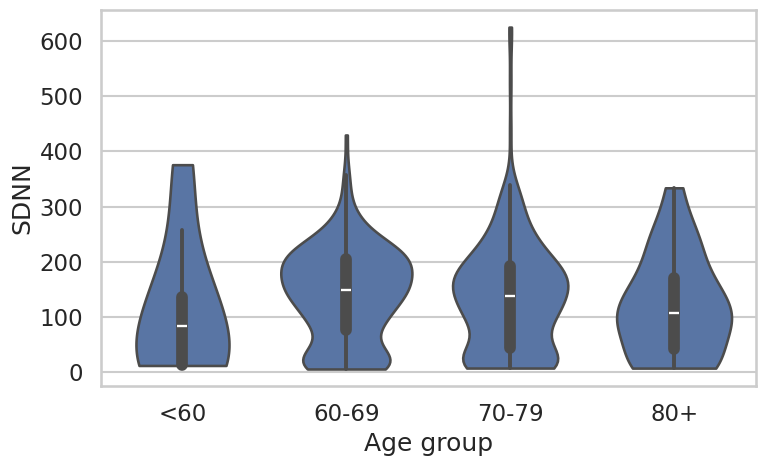

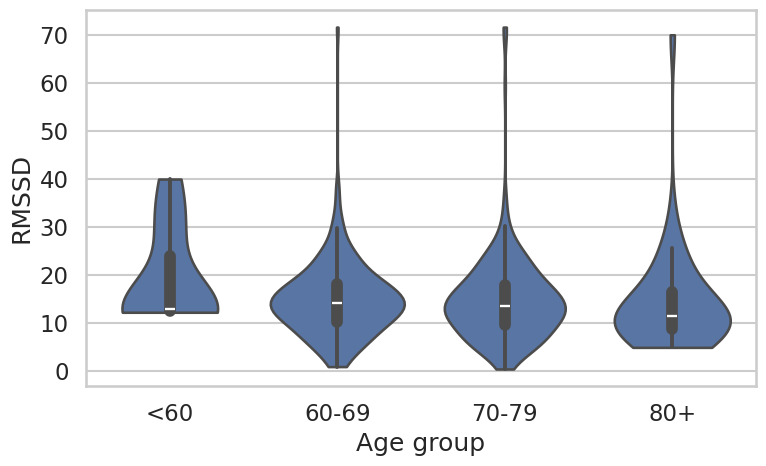

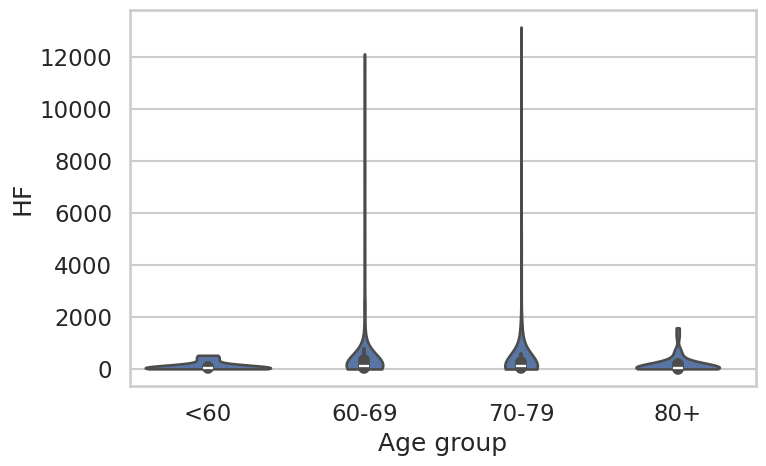

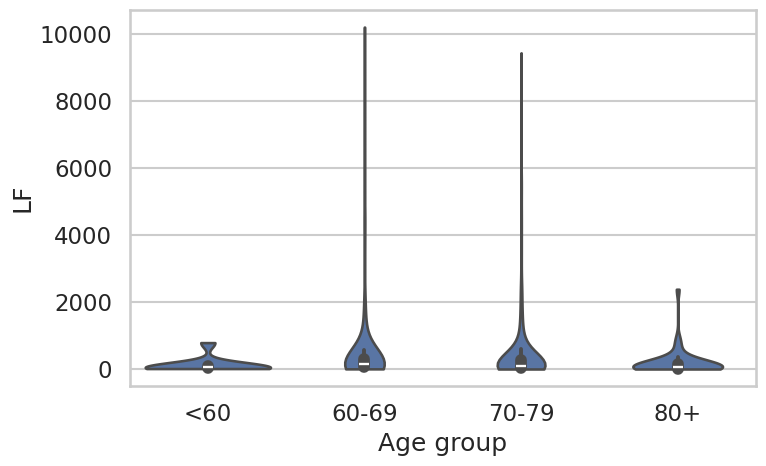

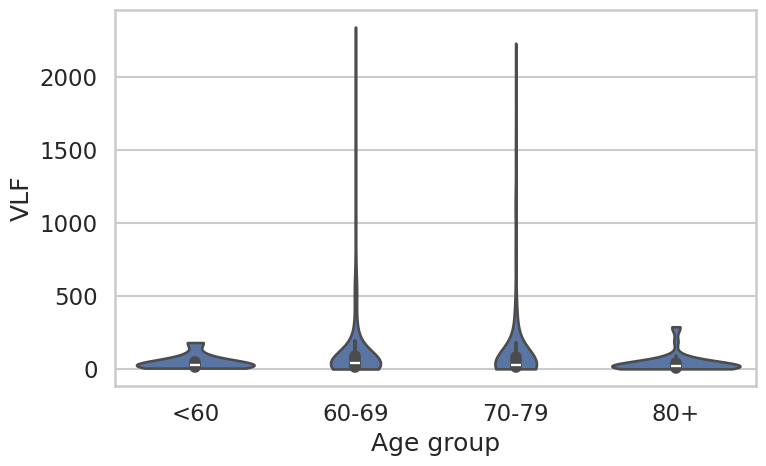

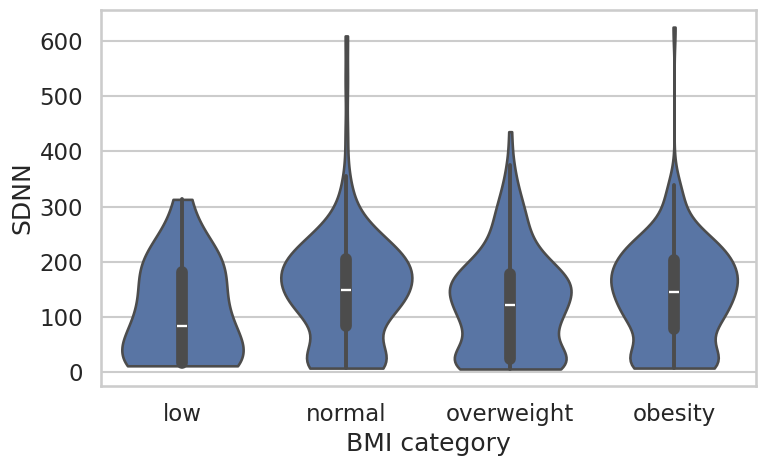

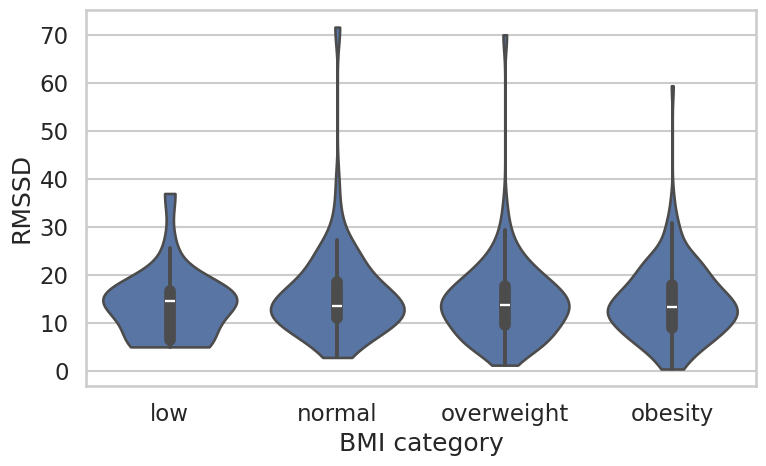

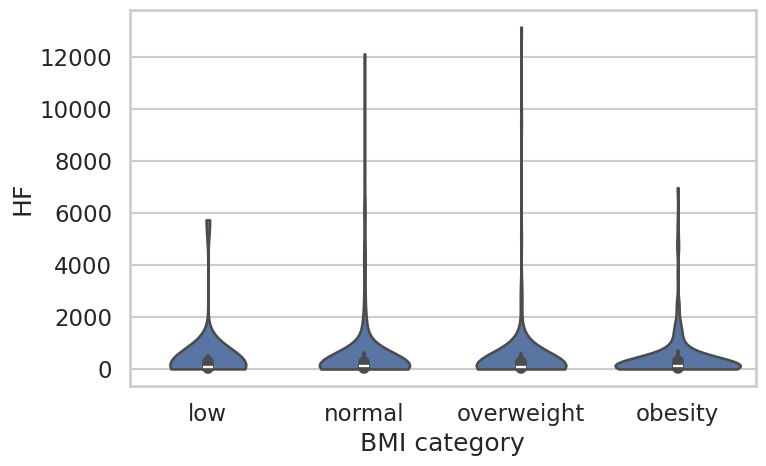

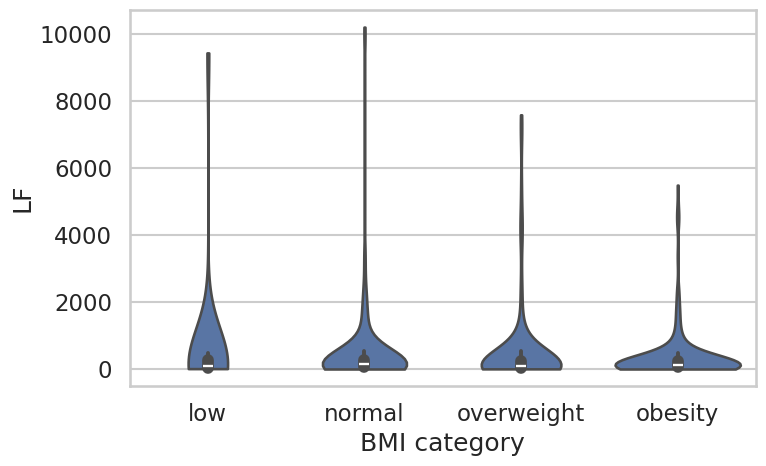

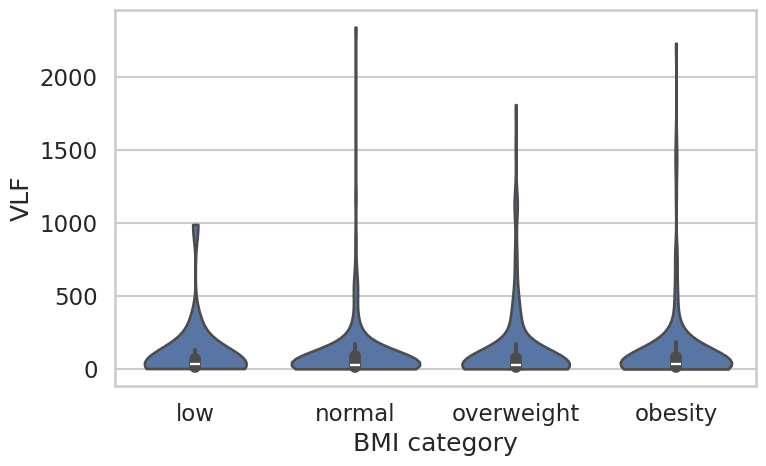

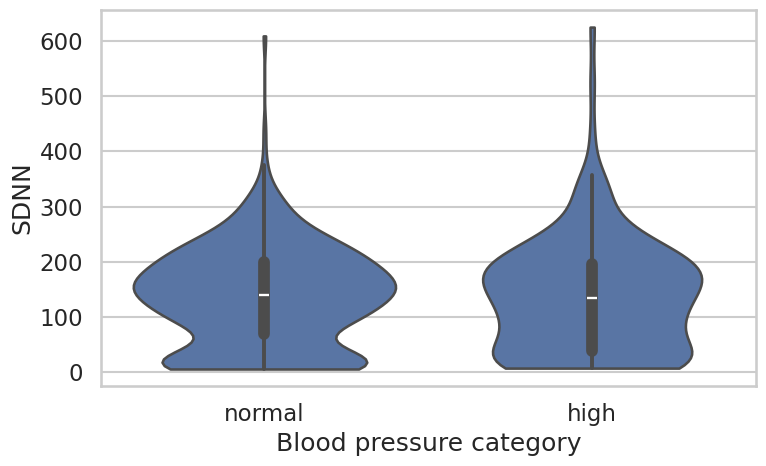

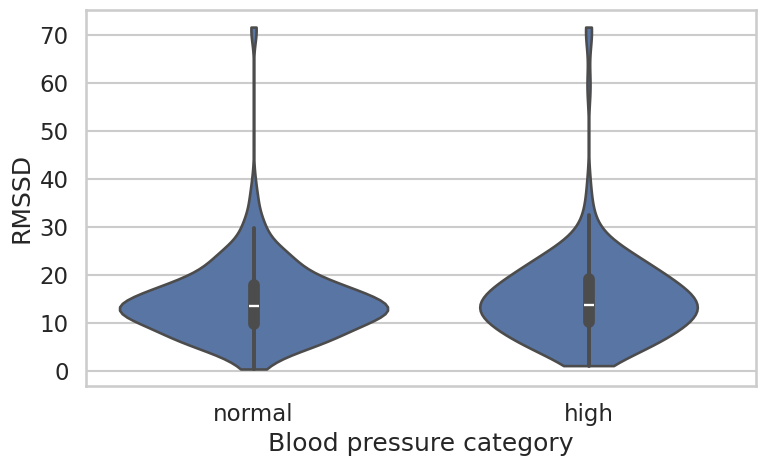

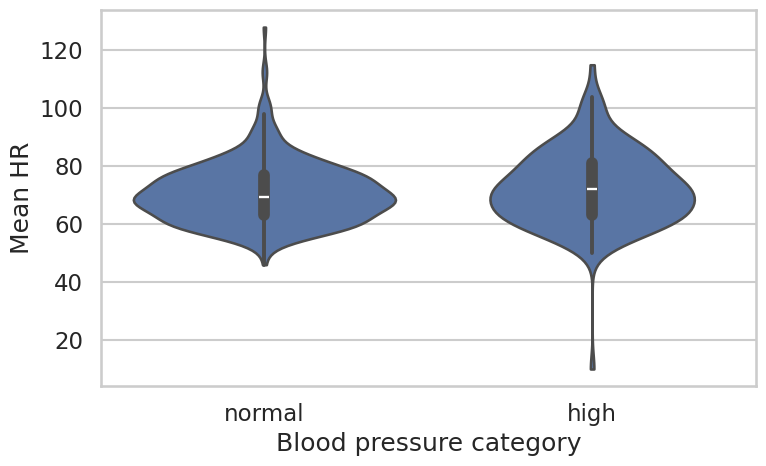

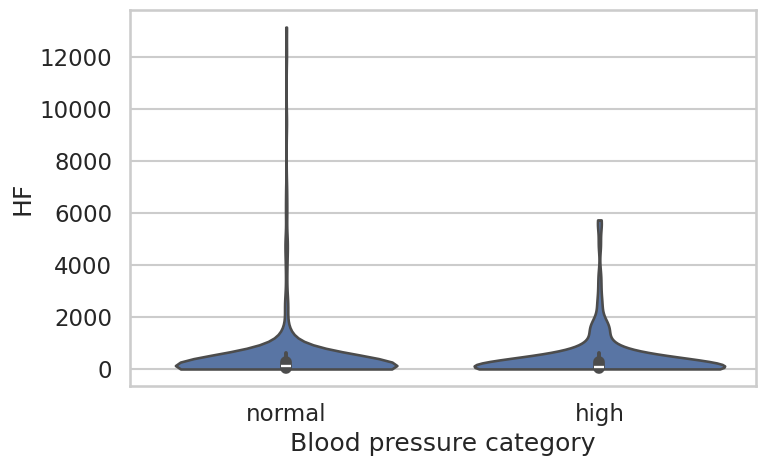

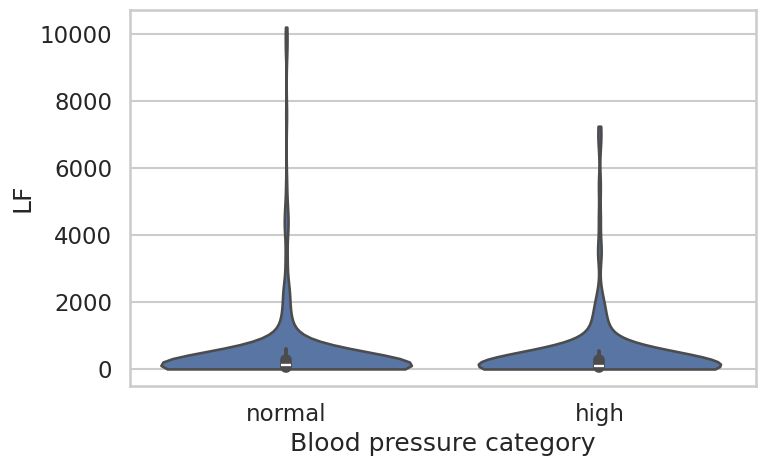

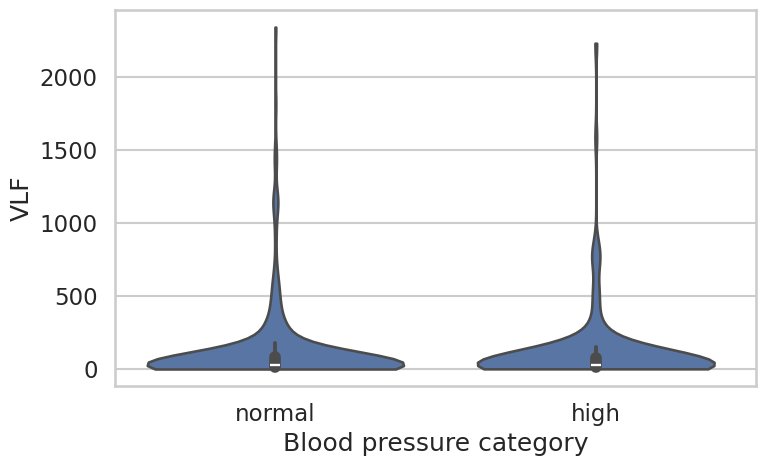

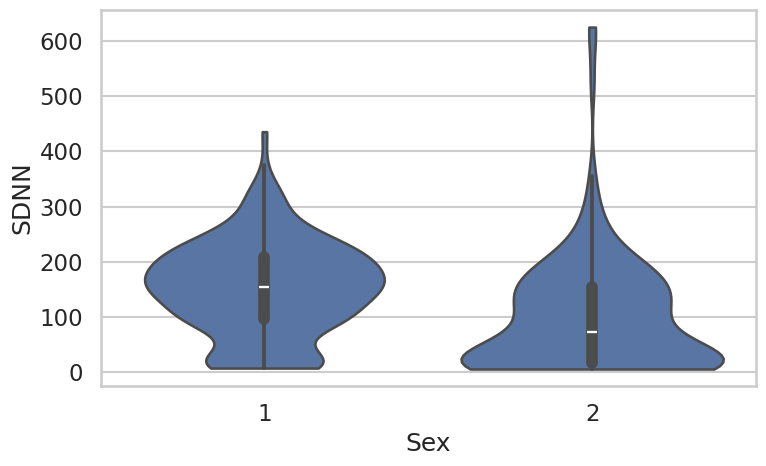

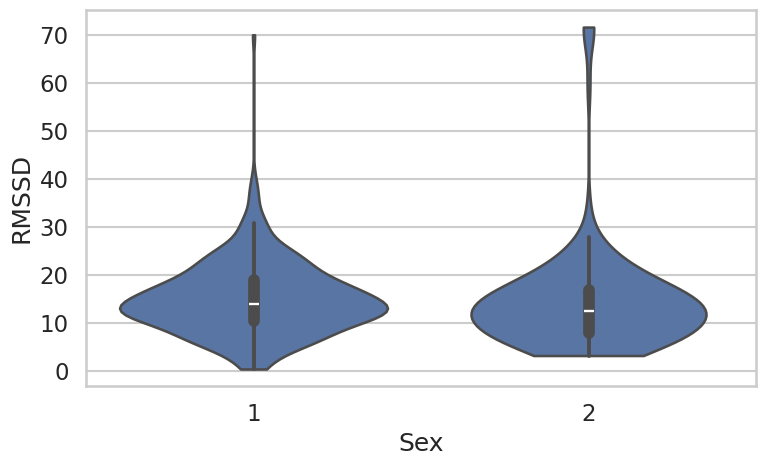

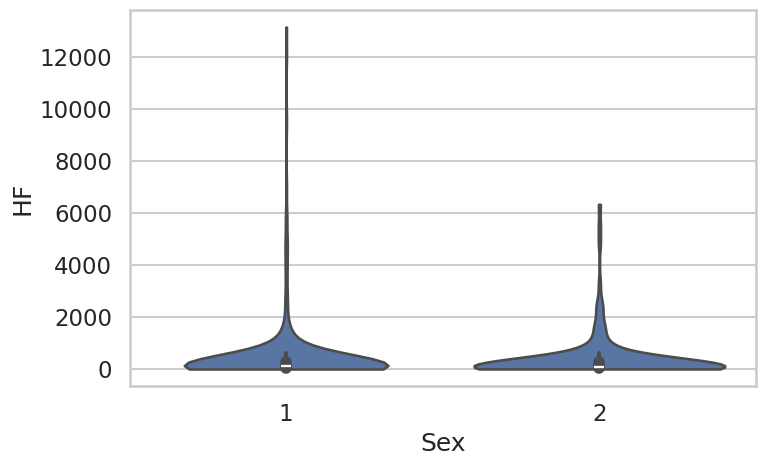

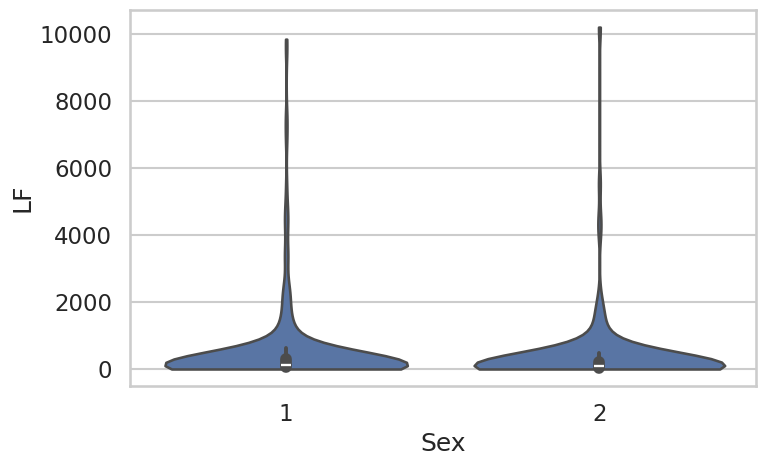

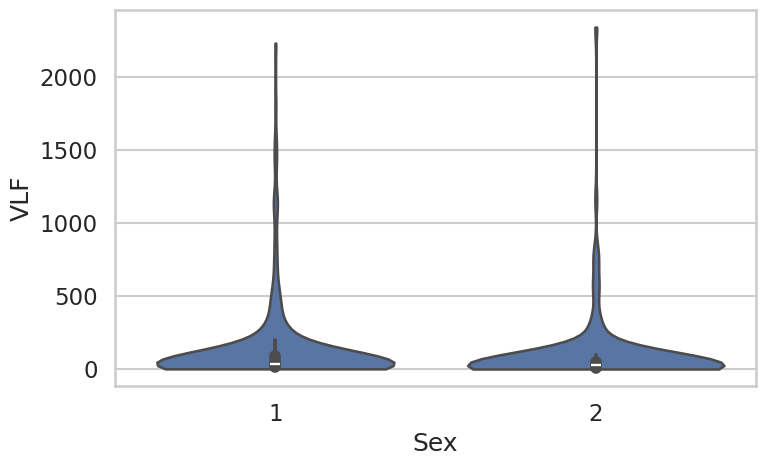

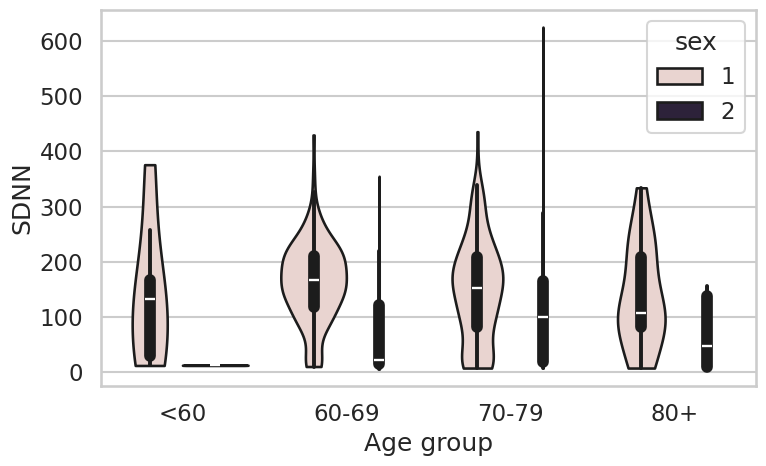

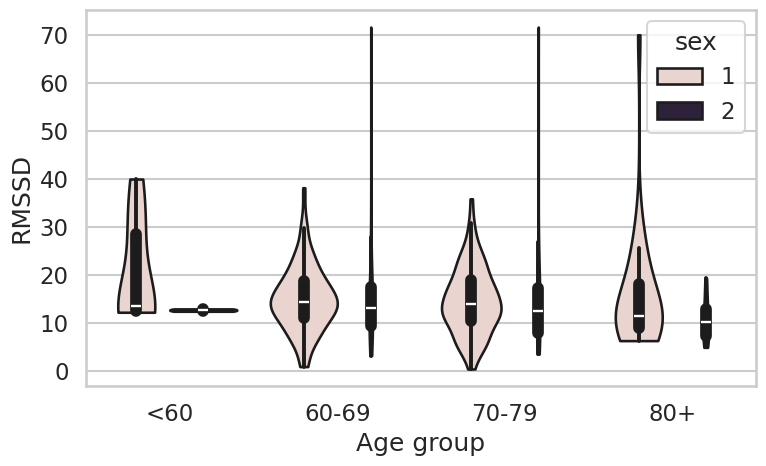

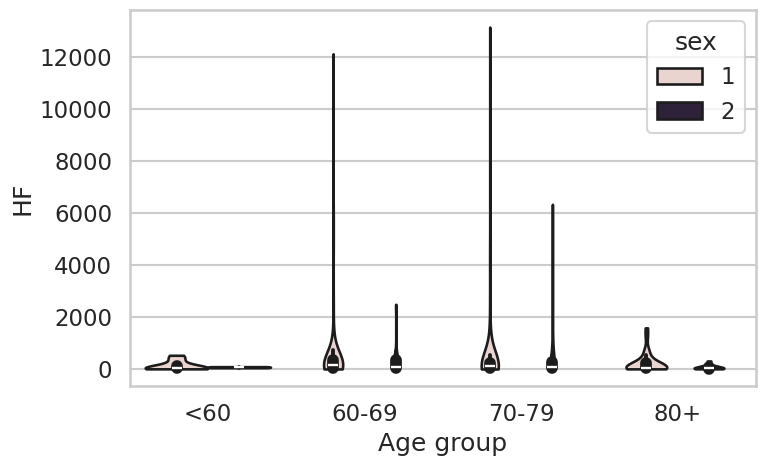

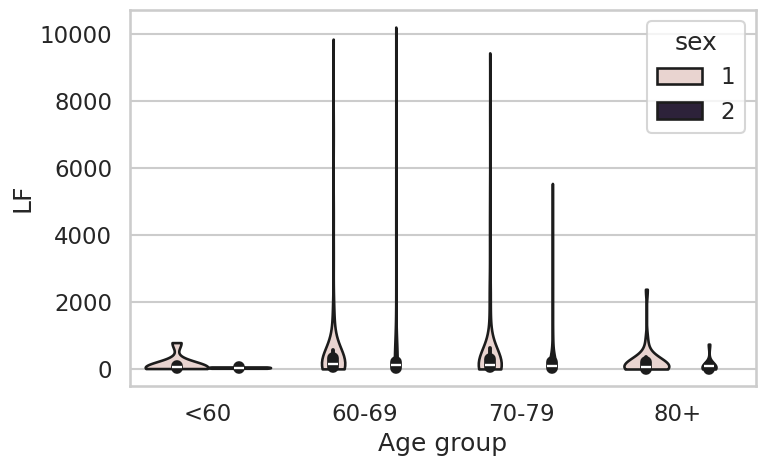

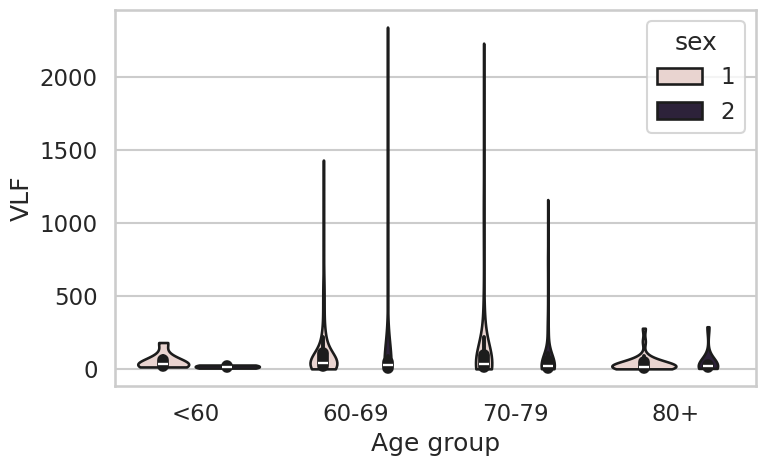

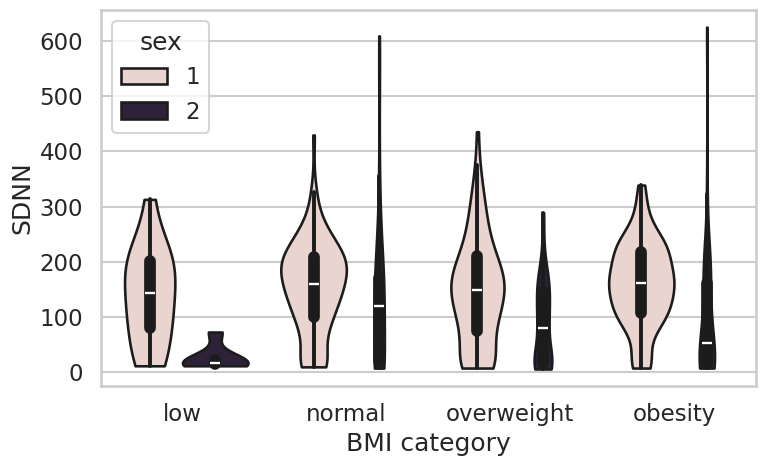

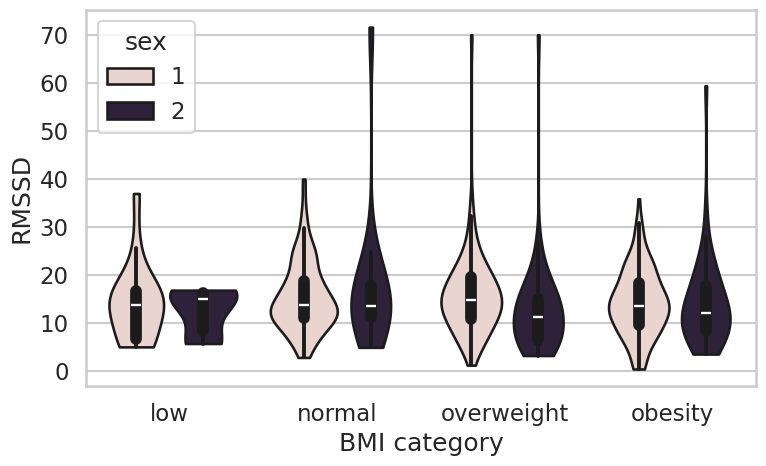

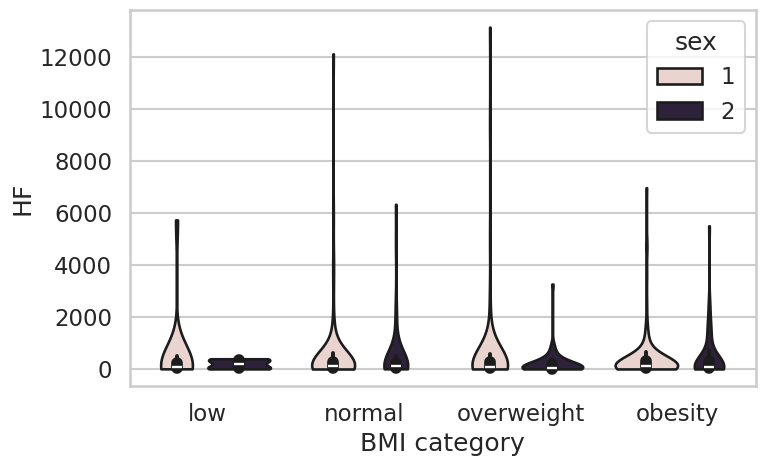

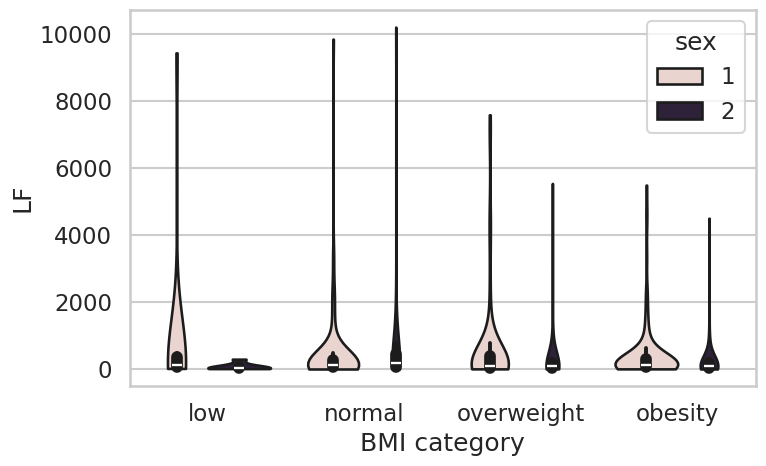

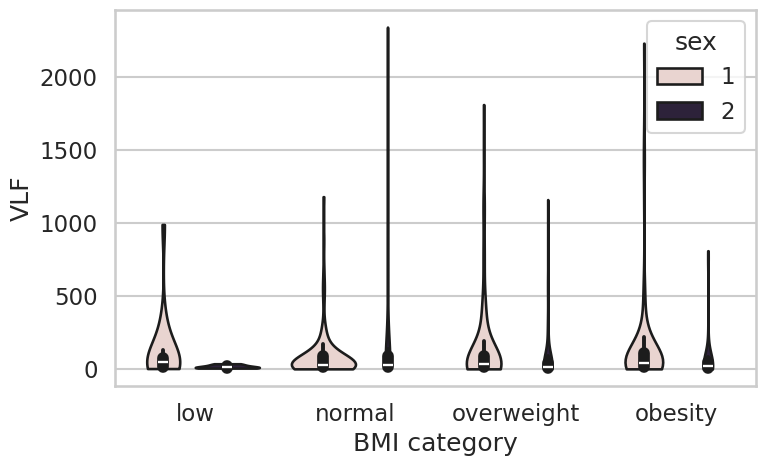

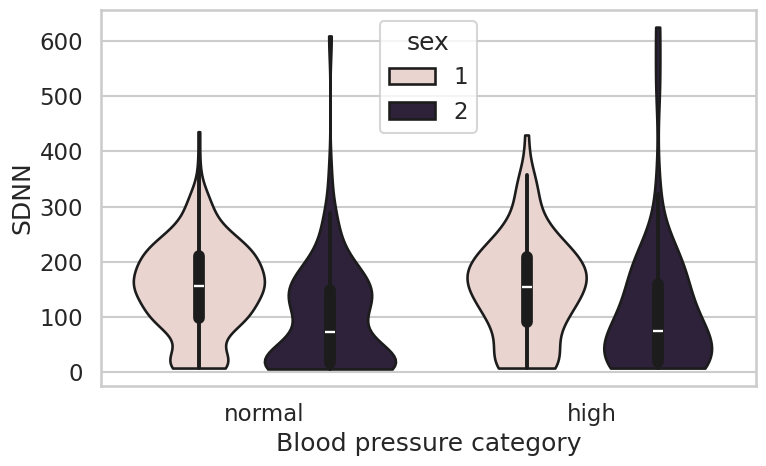

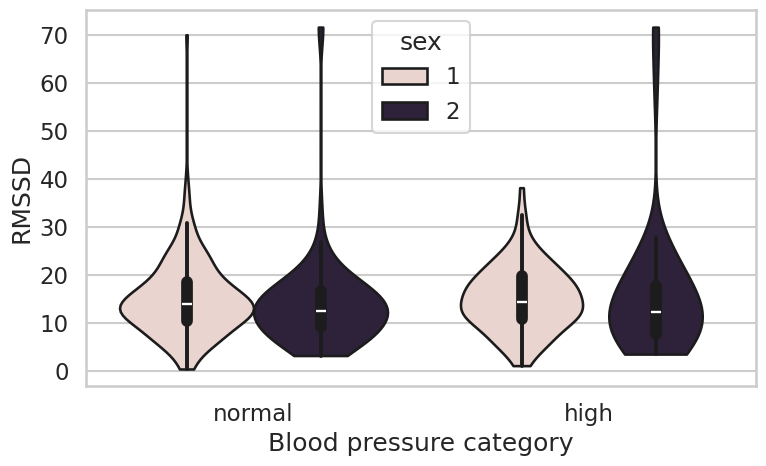

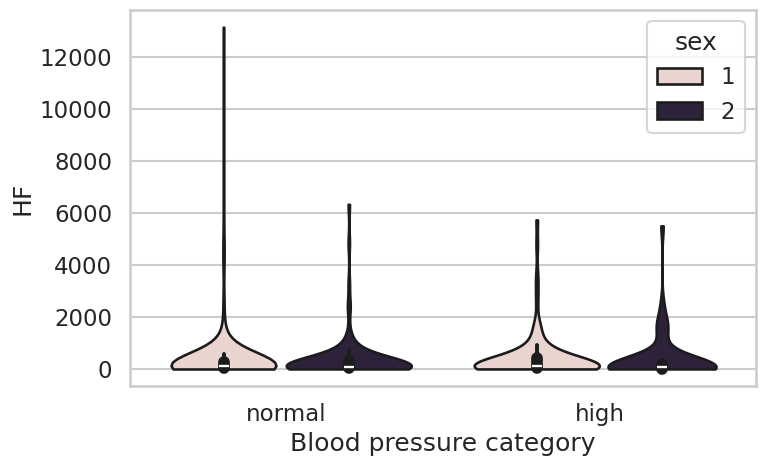

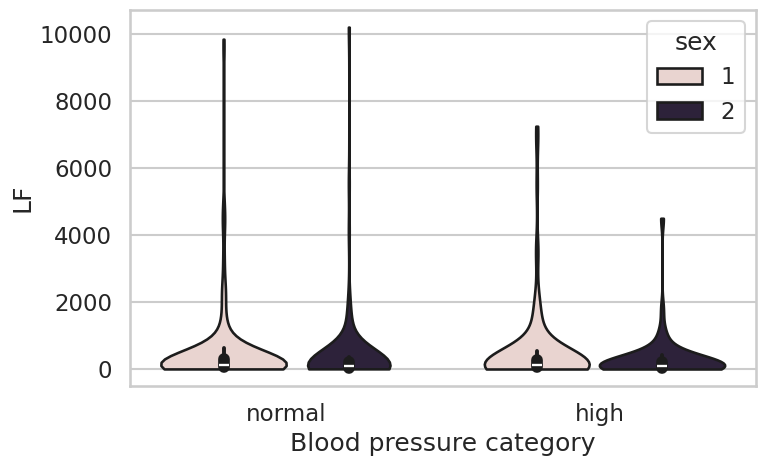

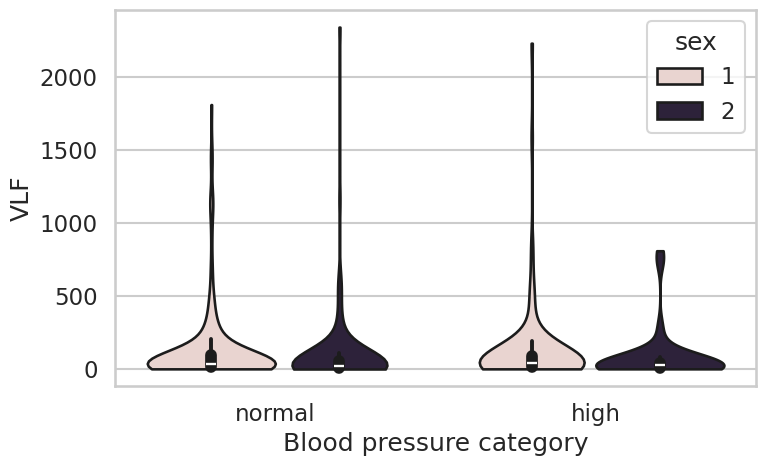

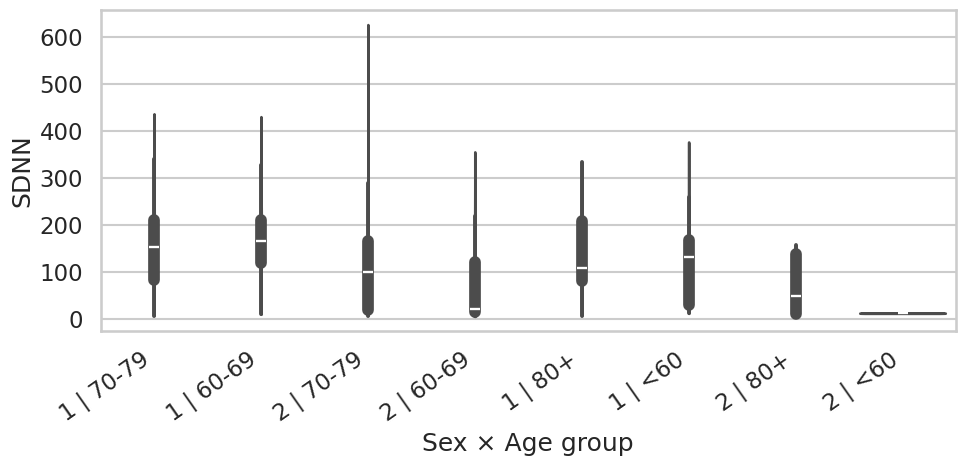

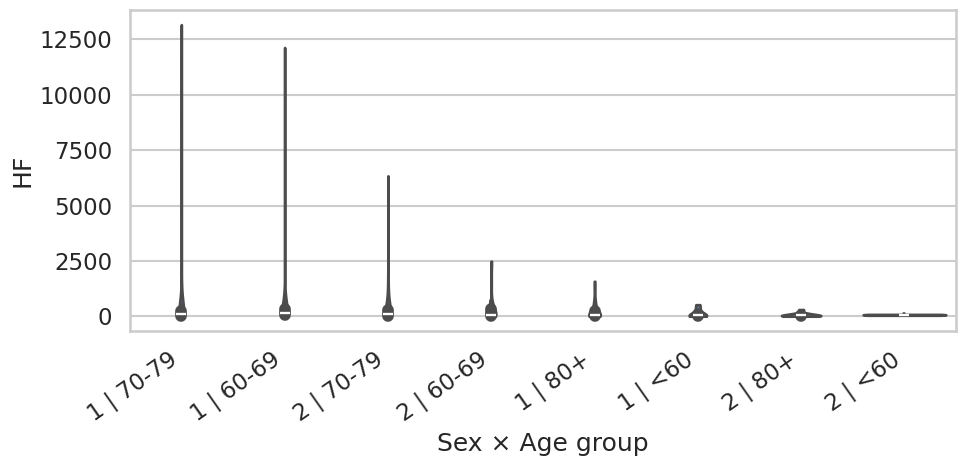

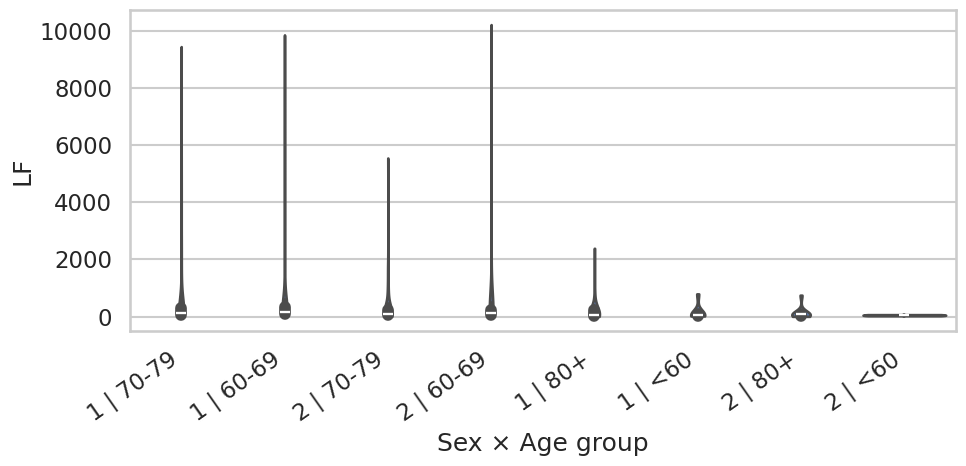

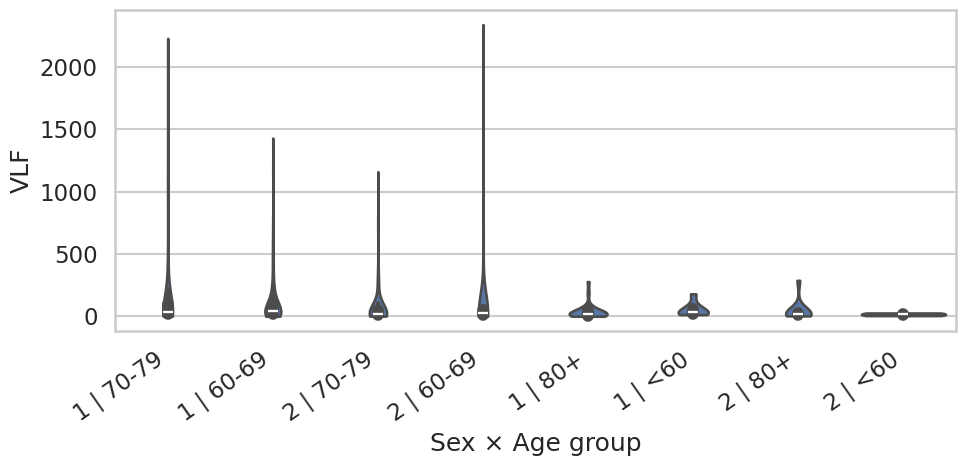

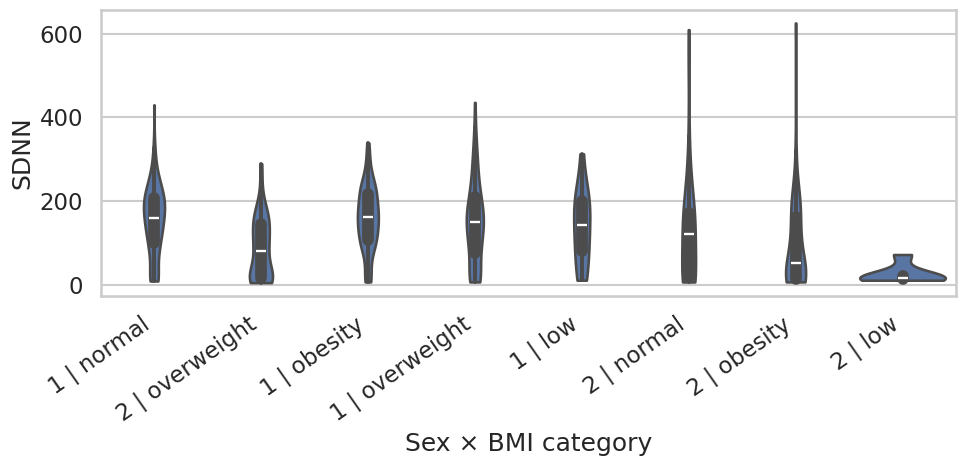

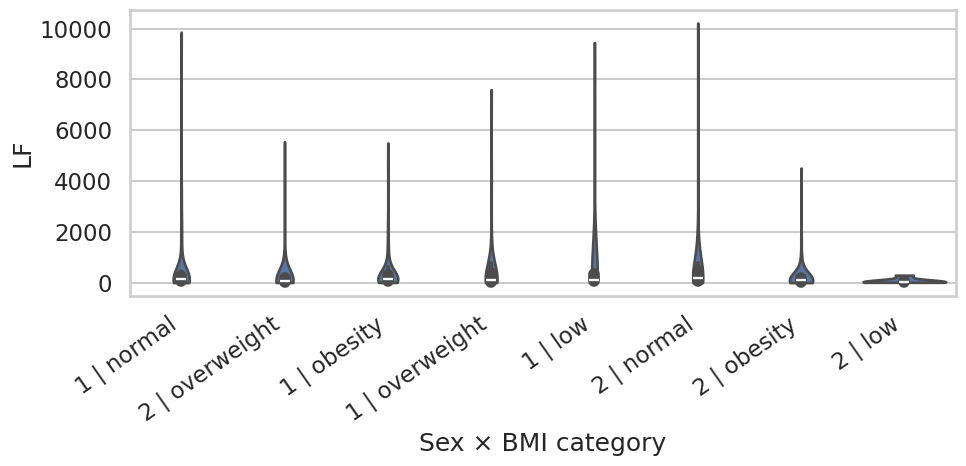

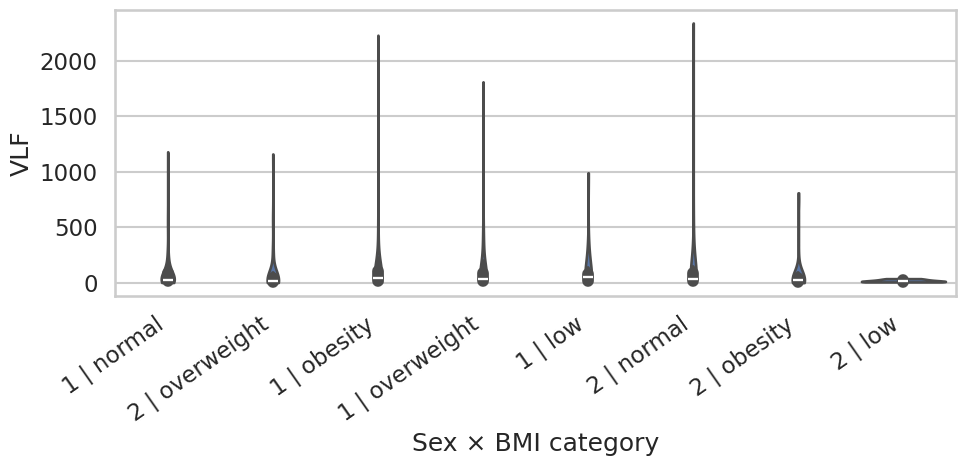

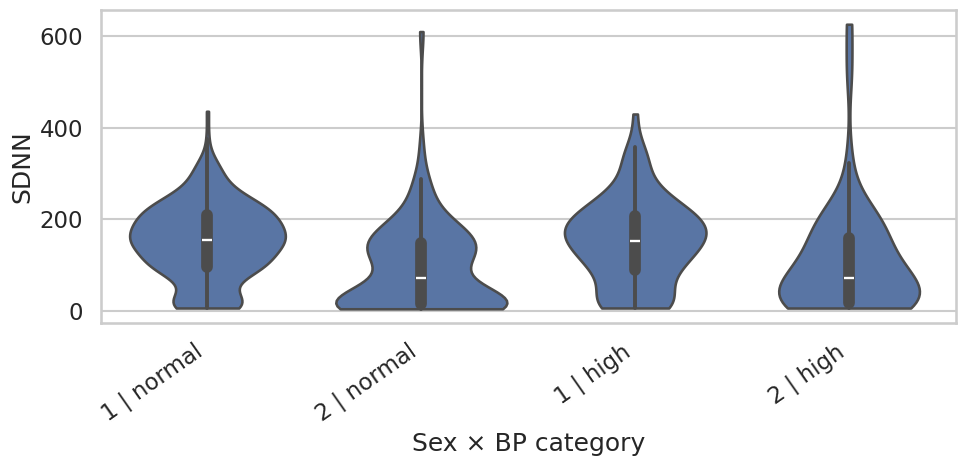

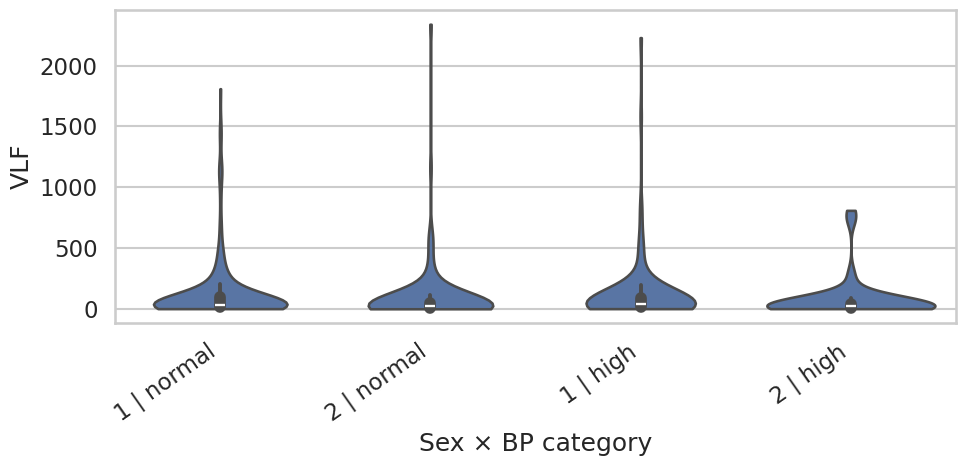

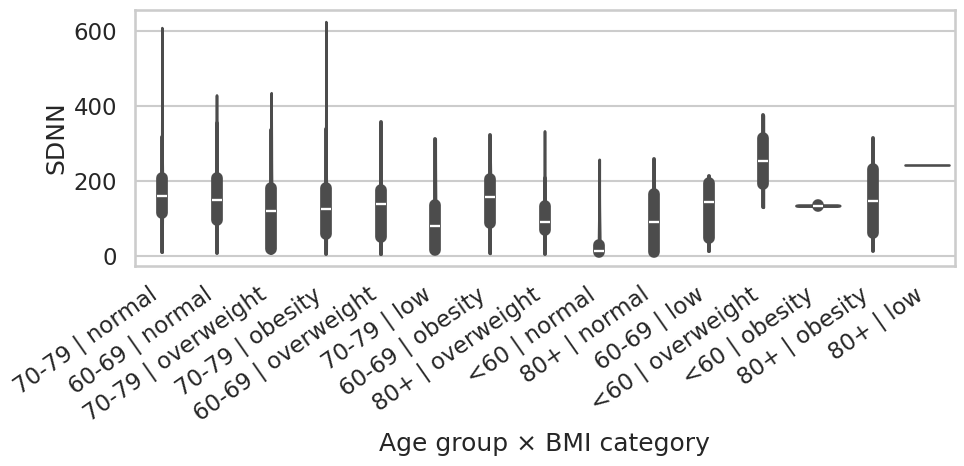

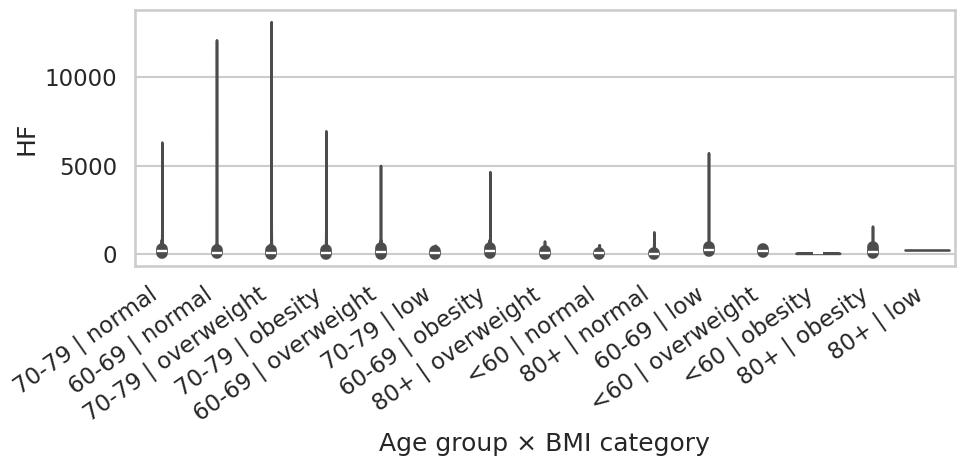

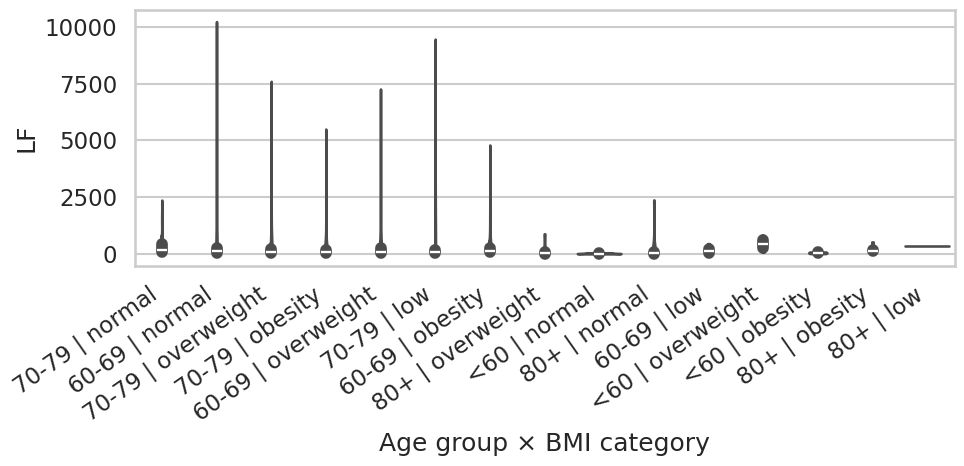

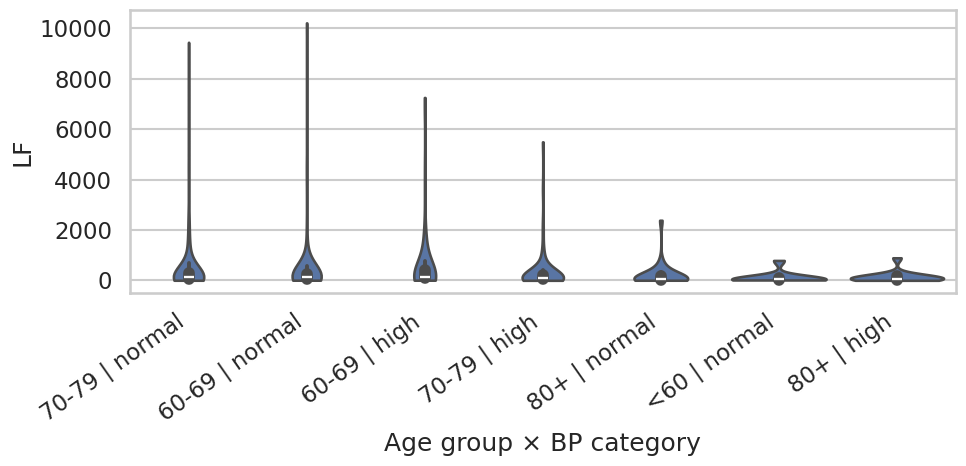

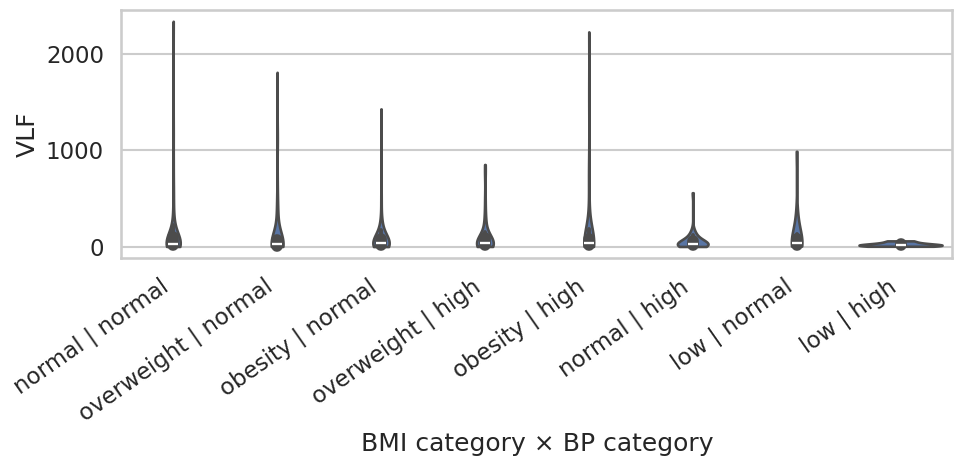

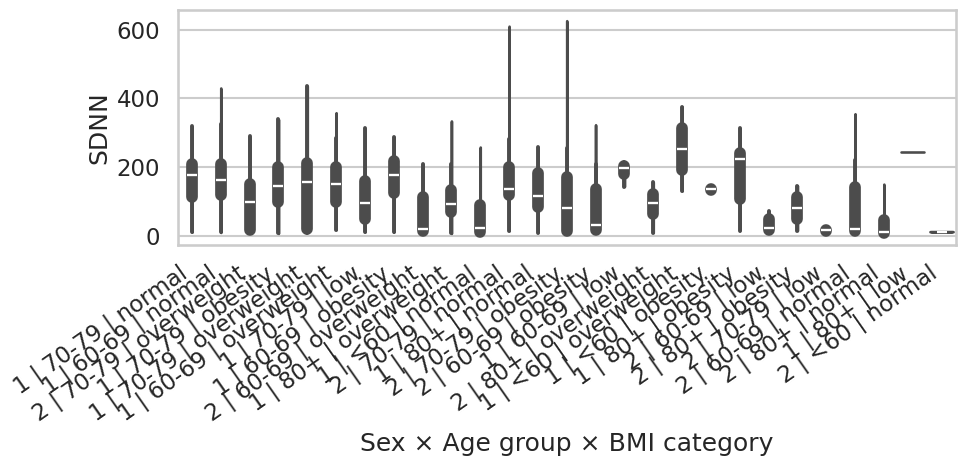

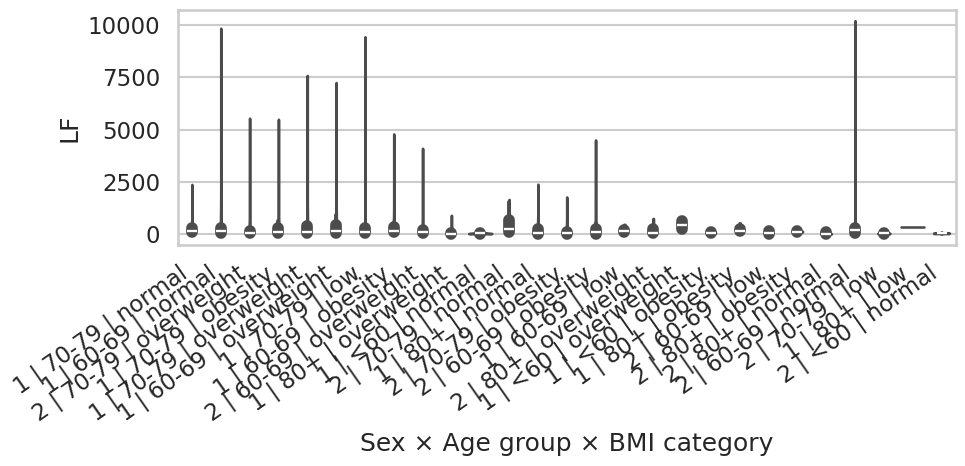

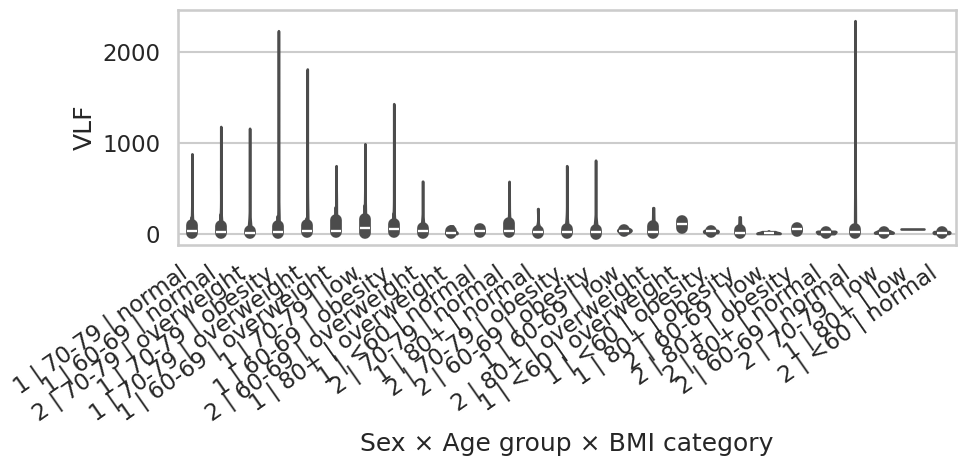

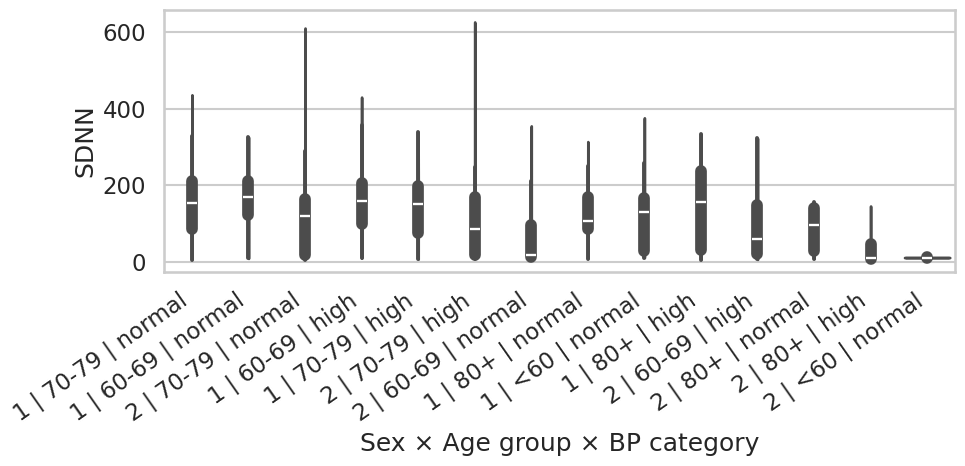

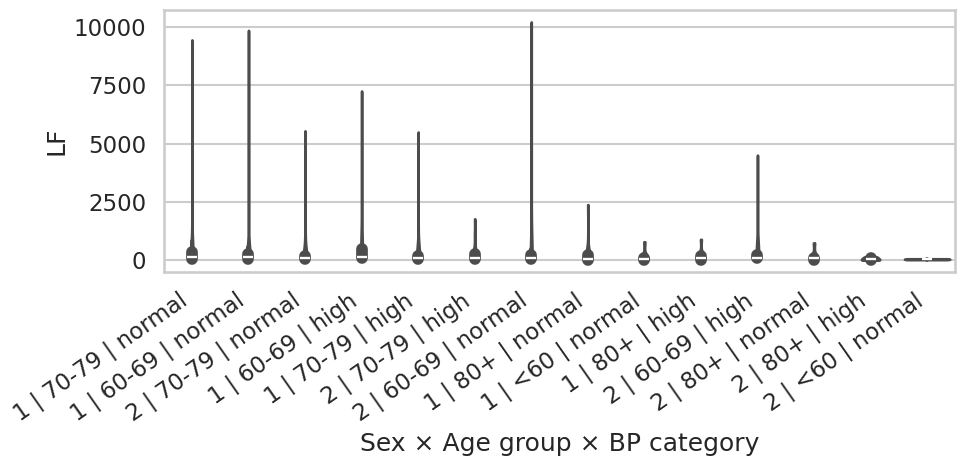

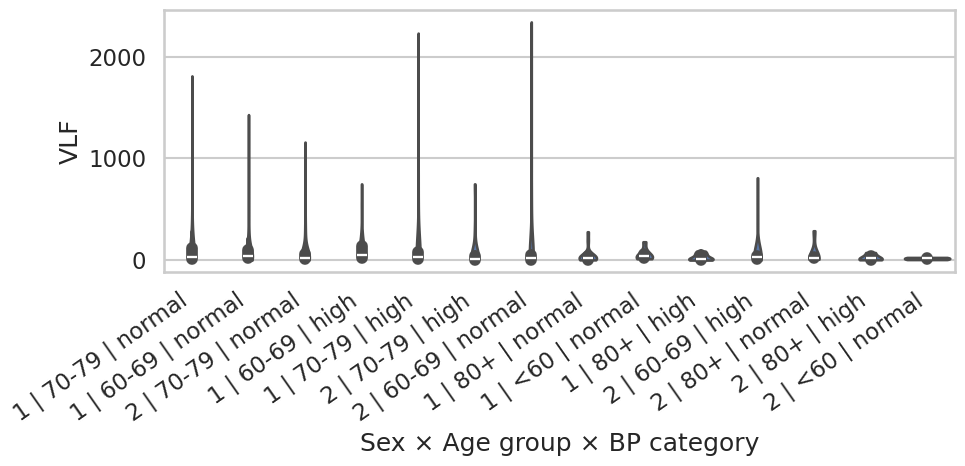

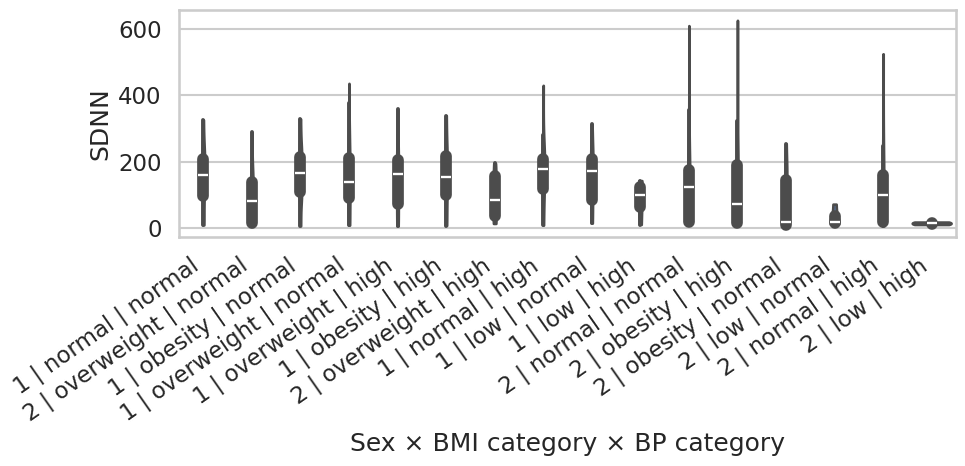

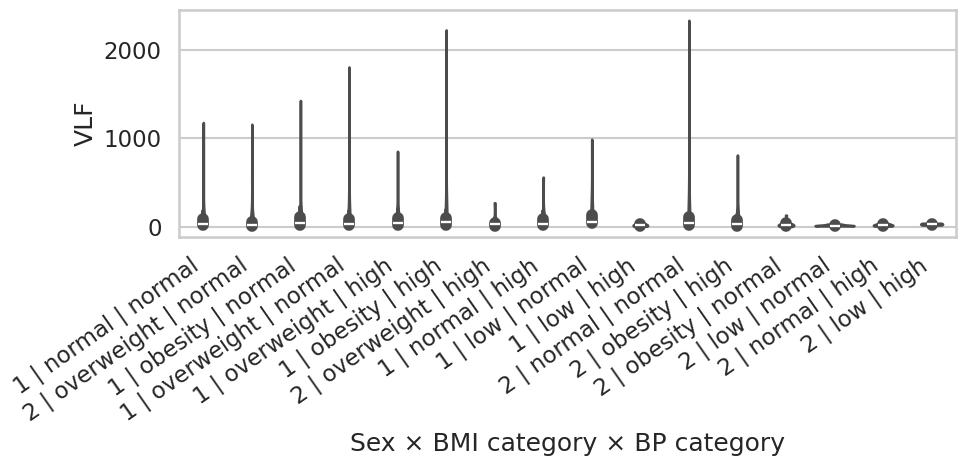

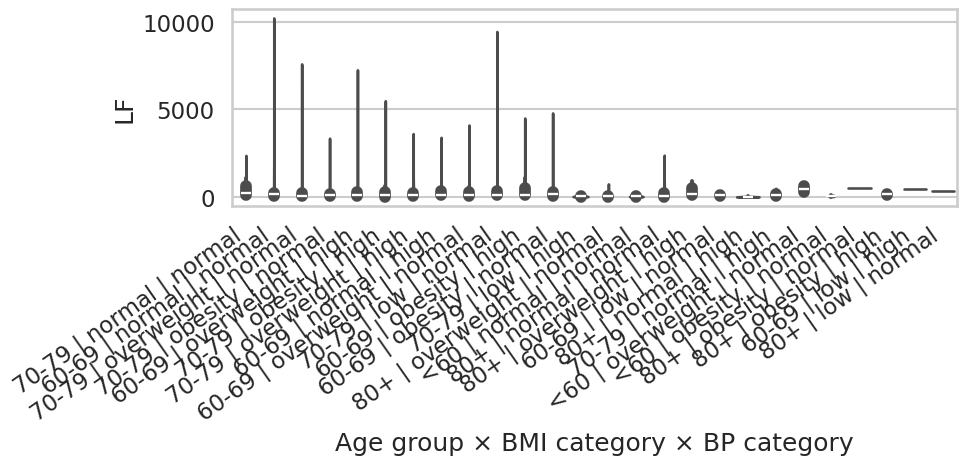

,group_col,value_col,hue_col,filename
0,age_group,t2m_pre_sdnn,None,paper_violin_age_group_t2m_pre_sdnn.png
1,age_group,t2m_pre_rmssd,None,paper_violin_age_group_t2m_pre_rmssd.png
2,age_group,t2m_pre_hf,None,paper_violin_age_group_t2m_pre_hf.png
3,age_group,t2m_pre_lf,None,paper_violin_age_group_t2m_pre_lf.png
4,age_group,t2m_pre_vlf,None,paper_violin_age_group_t2m_pre_vlf.png
5,bmi_cat,t2m_pre_sdnn,None,paper_violin_bmi_cat_t2m_pre_sdnn.png
6,bmi_cat,t2m_pre_rmssd,None,paper_violin_bmi_cat_t2m_pre_rmssd.png
7,bmi_cat,t2m_pre_hf,None,paper_violin_bmi_cat_t2m_pre_hf.png
8,bmi_cat,t2m_pre_lf,None,paper_violin_bmi_cat_t2m_pre_lf.png
9,bmi_cat,t2m_pre_vlf,None,paper_violin_bmi_cat_t2m_pre_vlf.png


In [53]:
key_plots = [
    # =========================
    # SIMPLE GROUPINGS
    # =========================
    ("age_group", "t2m_pre_sdnn", None),
    ("age_group", "t2m_pre_rmssd", None),
    ("age_group", "t2m_pre_hf", None),
    ("age_group", "t2m_pre_lf", None),
    ("age_group", "t2m_pre_vlf", None),

    ("bmi_cat", "t2m_pre_sdnn", None),
    ("bmi_cat", "t2m_pre_rmssd", None),
    ("bmi_cat", "t2m_pre_hf", None),
    ("bmi_cat", "t2m_pre_lf", None),
    ("bmi_cat", "t2m_pre_vlf", None),

    ("bp_cat", "t2m_pre_sdnn", None),
    ("bp_cat", "t2m_pre_rmssd", None),
    ("bp_cat", "t2m_pre_mean_hr", None),
    ("bp_cat", "t2m_pre_hf", None),
    ("bp_cat", "t2m_pre_lf", None),
    ("bp_cat", "t2m_pre_vlf", None),

    ("sex", "t2m_pre_sdnn", None),
    ("sex", "t2m_pre_rmssd", None),
    ("sex", "t2m_pre_hf", None),
    ("sex", "t2m_pre_lf", None),
    ("sex", "t2m_pre_vlf", None),

    # =========================
    # SIMPLE + HUE
    # =========================
    ("age_group", "t2m_pre_sdnn", "sex"),
    ("age_group", "t2m_pre_rmssd", "sex"),
    ("age_group", "t2m_pre_hf", "sex"),
    ("age_group", "t2m_pre_lf", "sex"),
    ("age_group", "t2m_pre_vlf", "sex"),

    ("bmi_cat", "t2m_pre_sdnn", "sex"),
    ("bmi_cat", "t2m_pre_rmssd", "sex"),
    ("bmi_cat", "t2m_pre_hf", "sex"),
    ("bmi_cat", "t2m_pre_lf", "sex"),
    ("bmi_cat", "t2m_pre_vlf", "sex"),

    ("bp_cat", "t2m_pre_sdnn", "sex"),
    ("bp_cat", "t2m_pre_rmssd", "sex"),
    ("bp_cat", "t2m_pre_hf", "sex"),
    ("bp_cat", "t2m_pre_lf", "sex"),
    ("bp_cat", "t2m_pre_vlf", "sex"),

    # =========================
    # DOUBLE COMBINATIONS
    # =========================
    ("sex__age_group", "t2m_pre_sdnn", None),
    ("sex__age_group", "t2m_pre_hf", None),
    ("sex__age_group", "t2m_pre_lf", None),
    ("sex__age_group", "t2m_pre_vlf", None),

    ("sex__bmi_cat", "t2m_pre_sdnn", None),
    ("sex__bmi_cat", "t2m_pre_lf", None),
    ("sex__bmi_cat", "t2m_pre_vlf", None),

    ("sex__bp_cat", "t2m_pre_sdnn", None),
    ("sex__bp_cat", "t2m_pre_vlf", None),

    ("age_group__bmi_cat", "t2m_pre_sdnn", None),
    ("age_group__bmi_cat", "t2m_pre_hf", None),
    ("age_group__bmi_cat", "t2m_pre_lf", None),

    ("age_group__bp_cat", "t2m_pre_lf", None),
    ("bmi_cat__bp_cat", "t2m_pre_vlf", None),

    # =========================
    # TRIPLE COMBINATIONS
    # =========================
    ("sex__age_group__bmi_cat", "t2m_pre_sdnn", None),
    ("sex__age_group__bmi_cat", "t2m_pre_lf", None),
    ("sex__age_group__bmi_cat", "t2m_pre_vlf", None),

    ("sex__age_group__bp_cat", "t2m_pre_sdnn", None),
    ("sex__age_group__bp_cat", "t2m_pre_lf", None),
    ("sex__age_group__bp_cat", "t2m_pre_vlf", None),

    ("sex__bmi_cat__bp_cat", "t2m_pre_sdnn", None),
    ("sex__bmi_cat__bp_cat", "t2m_pre_vlf", None),

    ("age_group__bmi_cat__bp_cat", "t2m_pre_lf", None),
]

generated_plots = []

for group_col, value_col, hue_col in key_plots:
    if group_col in df.columns and value_col in df.columns:
        fname = f"paper_violin_{group_col}_{value_col}" + (f"_hue_{hue_col}" if hue_col else "") + ".png"
        
        rotation = 0 if group_col in ["sex", "age_group", "bmi_cat", "bp_cat"] else 35
        figsize = (10, 5) if "__" in group_col else (8, 5)

        plot_paper_ready_violin(
            df_in=df,
            group_col=group_col,
            value_col=value_col,
            hue_col=hue_col,
            filename=fname,
            figsize=figsize,
            rotation=rotation
        )
        
        generated_plots.append({
            "group_col": group_col,
            "value_col": value_col,
            "hue_col": hue_col,
            "filename": fname
        })

generated_plots_df = pd.DataFrame(generated_plots)
generated_plots_df

In [42]:
narrative_rows = []

if not kruskal_df.empty:
    for _, row in kruskal_df[kruskal_df["significant_fdr"]].iterrows():
        narrative_rows.append({
            "analysis_level": "single",
            "grouping": pretty_group_name(row["grouping_variable"]),
            "hrv_metric": pretty_hrv_name(row["value_variable"]),
            "effect_size": row["epsilon_squared"],
            "p_adj_fdr": row["p_adj_fdr"],
            "interpretation": f"{pretty_hrv_name(row['value_variable'])} differed across {pretty_group_name(row['grouping_variable'])} groups."
        })

if not double_kruskal_df.empty:
    for _, row in double_kruskal_df[double_kruskal_df["significant_fdr"]].iterrows():
        narrative_rows.append({
            "analysis_level": "double",
            "grouping": pretty_group_name(row["combined_grouping"]),
            "hrv_metric": pretty_hrv_name(row["value_variable"]),
            "effect_size": row["epsilon_squared"],
            "p_adj_fdr": row["p_adj_fdr"],
            "interpretation": f"{pretty_hrv_name(row['value_variable'])} differed across combined categories of {pretty_group_name(row['combined_grouping'])}."
        })

if not triple_kruskal_df.empty:
    for _, row in triple_kruskal_df[triple_kruskal_df["significant_fdr"]].iterrows():
        narrative_rows.append({
            "analysis_level": "triple",
            "grouping": pretty_group_name(row["combined_grouping"]),
            "hrv_metric": pretty_hrv_name(row["value_variable"]),
            "effect_size": row["epsilon_squared"],
            "p_adj_fdr": row["p_adj_fdr"],
            "interpretation": f"{pretty_hrv_name(row['value_variable'])} differed across higher-order combined categories of {pretty_group_name(row['combined_grouping'])}."
        })

narrative_df = pd.DataFrame(narrative_rows).sort_values(["p_adj_fdr", "effect_size"], ascending=[True, False])
narrative_df.head(30)

,analysis_level,grouping,hrv_metric,effect_size,p_adj_fdr,interpretation
2,double,Sex × Age group,SDNN,0.110154,1.135862e-10,SDNN differed across combined categories of Se...
9,double,Sex × BP category,SDNN,0.096528,1.478346e-10,SDNN differed across combined categories of Se...
6,double,Sex × BMI category,SDNN,0.106307,5.748690e-10,SDNN differed across combined categories of Se...
18,triple,Sex × Age group × BP category,SDNN,0.094717,9.413797e-08,SDNN differed across higher-order combined cat...
15,triple,Sex × Age group × BMI category,SDNN,0.105974,1.904127e-07,SDNN differed across higher-order combined cat...
21,triple,Sex × BMI category × BP category,SDNN,0.087915,9.863993e-07,SDNN differed across higher-order combined cat...
13,double,Age group × BMI category,LF,0.059610,1.340203e-04,LF differed across combined categories of Age ...
16,triple,Sex × Age group × BMI category,LF,0.054892,8.196635e-04,LF differed across higher-order combined categ...
5,double,Sex × Age group,VLF,0.035673,1.173355e-03,VLF differed across combined categories of Sex...
4,double,Sex × Age group,LF,0.034720,1.173355e-03,LF differed across combined categories of Sex ...


In [43]:
narrative_df.to_csv(TABLE_DIR / "narrative_summary_of_significant_results.csv", index=False)

In [44]:
final_results_table = []

if not kruskal_df.empty:
    tmp = kruskal_df[kruskal_df["significant_fdr"]].copy()
    tmp["analysis_level"] = "single"
    tmp["grouping_label"] = tmp["grouping_variable"].map(pretty_group_name)
    tmp["hrv_label"] = tmp["value_variable"].map(pretty_hrv_name)
    final_results_table.append(
        tmp[["analysis_level", "grouping_label", "hrv_label", "h_stat", "p_adj_fdr", "epsilon_squared"]]
    )

if not double_kruskal_df.empty:
    tmp = double_kruskal_df[double_kruskal_df["significant_fdr"]].copy()
    tmp["analysis_level"] = "double"
    tmp["grouping_label"] = tmp["combined_grouping"].map(pretty_group_name)
    tmp["hrv_label"] = tmp["value_variable"].map(pretty_hrv_name)
    final_results_table.append(
        tmp[["analysis_level", "grouping_label", "hrv_label", "h_stat", "p_adj_fdr", "epsilon_squared"]]
    )

if not triple_kruskal_df.empty:
    tmp = triple_kruskal_df[triple_kruskal_df["significant_fdr"]].copy()
    tmp["analysis_level"] = "triple"
    tmp["grouping_label"] = tmp["combined_grouping"].map(pretty_group_name)
    tmp["hrv_label"] = tmp["value_variable"].map(pretty_hrv_name)
    final_results_table.append(
        tmp[["analysis_level", "grouping_label", "hrv_label", "h_stat", "p_adj_fdr", "epsilon_squared"]]
    )

final_results_df = pd.concat(final_results_table, ignore_index=True) if final_results_table else pd.DataFrame()
final_results_df = final_results_df.sort_values(["analysis_level", "p_adj_fdr", "epsilon_squared"], ascending=[True, True, False])
final_results_df

,analysis_level,grouping_label,hrv_label,h_stat,p_adj_fdr,epsilon_squared
2,double,Sex × Age group,SDNN,62.178469,1.135862e-10,0.110154
9,double,Sex × BP category,SDNN,52.711849,1.478346e-10,0.096528
6,double,Sex × BMI category,SDNN,61.322907,5.748690e-10,0.106307
13,double,Age group × BMI category,LF,41.579853,1.340203e-04,0.059610
5,double,Sex × Age group,VLF,24.585871,1.173355e-03,0.035673
4,double,Sex × Age group,LF,24.089311,1.173355e-03,0.034720
10,double,Sex × BP category,VLF,16.227945,3.563895e-03,0.025148
8,double,Sex × BMI category,VLF,22.617240,6.953825e-03,0.029918
12,double,Age group × BMI category,HF,28.749194,8.688387e-03,0.034599
14,double,Age group × BP category,LF,21.689971,9.645044e-03,0.030000


In [45]:
final_results_df.to_csv(TABLE_DIR / "final_results_table_for_paper.csv", index=False)

In [46]:
executive_summary = {
    "best_single_grouping": None if kruskal_df.empty else pretty_group_name(
        kruskal_df.sort_values(["epsilon_squared", "p_adj_fdr"], ascending=[False, True]).iloc[0]["grouping_variable"]
    ),
    "best_single_hrv": None if kruskal_df.empty else pretty_hrv_name(
        kruskal_df.sort_values(["epsilon_squared", "p_adj_fdr"], ascending=[False, True]).iloc[0]["value_variable"]
    ),
    "best_double_grouping": None if double_kruskal_df.empty else pretty_group_name(
        double_kruskal_df.sort_values(["epsilon_squared", "p_adj_fdr"], ascending=[False, True]).iloc[0]["combined_grouping"]
    ),
    "best_double_hrv": None if double_kruskal_df.empty else pretty_hrv_name(
        double_kruskal_df.sort_values(["epsilon_squared", "p_adj_fdr"], ascending=[False, True]).iloc[0]["value_variable"]
    ),
    "best_triple_grouping": None if triple_kruskal_df.empty else pretty_group_name(
        triple_kruskal_df.sort_values(["epsilon_squared", "p_adj_fdr"], ascending=[False, True]).iloc[0]["combined_grouping"]
    ),
    "best_triple_hrv": None if triple_kruskal_df.empty else pretty_hrv_name(
        triple_kruskal_df.sort_values(["epsilon_squared", "p_adj_fdr"], ascending=[False, True]).iloc[0]["value_variable"]
    ),
}

pd.Series(executive_summary, name="value")

best_single_grouping                         Age group
best_single_hrv                                     LF
best_double_grouping                   Sex × Age group
best_double_hrv                                   SDNN
best_triple_grouping    Sex × Age group × BMI category
best_triple_hrv                                   SDNN
Name: value, dtype: object

In [47]:
pd.Series(executive_summary, name="value").to_csv(TABLE_DIR / "executive_summary.csv")